# APF3 · Solución de Machine Learning para TITAN GYM
**Curso:** Innovación y Transformación Digital (UTP, 2026-2) · **Grupo 6**

**Integrantes:** Campos Ortiz, Yorman Alexander · Cerna Martinez, Arian · Rojas Reyes, Fabrizio Marcelo · Arbi Pando, Manuel Sebastian

**MiPYME:** TITAN GYM (RUC 20602718931), sede Qatuna, Carabayllo · **MVP (APF2):** FitSmart Agenda — https://titan-gym-tau.vercel.app

**Problema de ingeniería (APF1, sin cambios):** falta de un sistema de reservas y agenda automatizado con un modelo
predictivo de no-shows para optimizar la ocupación de aforos y reducir las inasistencias no avisadas.
**Indicador:** porcentaje de inasistencias no avisadas (no-shows).

### Cómo ejecutar
* **Local / Jupyter:** desde la carpeta `ml/` del repositorio: `pip install -r requirements.txt` y *Run All*.
* **Google Colab:** abrir el notebook y ejecutar todo; la primera celda instala las dependencias y descarga
  los módulos `simulacion.py`, `titan_noshow.py` e `integracion/` del repositorio público si no están presentes.

Todo el notebook usa `random_state = 2026` y corre de principio a fin sin intervención.

> **Aviso de datos:** el dataset de este notebook es **100 % simulado** (columna `origen = "simulado"`), porque el MVP
> todavía no registra asistencia real suficiente. Los resultados son **indicativos y no generalizables** hasta
> reentrenar con asistencia real exportada desde el panel `/admin` del MVP.

In [1]:
# Instalación de dependencias: solo es necesaria en Google Colab. En local: pip install -r requirements.txt
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "scikit-learn==1.5.2", "fastapi==0.115.5", "httpx==0.27.2"])

## 0. Configuración del entorno
Bloque de **carga**: librerías, semilla global, rutas de salida y módulos del proyecto.

In [2]:
import json
import os
import platform
import sys
import time
import warnings
from pathlib import Path

BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
REPO_RAW = "https://raw.githubusercontent.com/ariancerna/Titan-Gym/main/ml/"
MODULOS = ["simulacion.py", "titan_noshow.py", "integracion/__init__.py", "integracion/predict.py", "integracion/api.py"]
for modulo in MODULOS:  # en Colab descarga los módulos del repositorio si no están junto al notebook
    destino = BASE / modulo
    if not destino.exists():
        import urllib.request

        destino.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + modulo, destino)
sys.path.insert(0, str(BASE))

import joblib
import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")  # ejecución como script: sin ventanas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

import simulacion
import titan_noshow as tn

warnings.filterwarnings("ignore", category=FutureWarning)
# joblib intenta contar núcleos físicos con wmic (ausente en Windows 11) y avisa; un tope explícito lo evita.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, (os.cpu_count() or 2) - 1)))
try:  # consola de Windows: imprimir tildes y símbolos
    sys.stdout.reconfigure(encoding="utf-8")
except AttributeError:
    pass
SEED = 2026
np.random.seed(SEED)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")

DATA, FIG, MODELO = BASE / "data", BASE / "figuras", BASE / "modelo"
for carpeta in (DATA, FIG, MODELO):
    carpeta.mkdir(exist_ok=True)


def mostrar(obj):
    """display() en Jupyter; print() cuando se ejecuta como script."""
    try:
        display(obj)  # noqa: F821
    except NameError:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


def guardar(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches="tight")
    if "ipykernel" in sys.modules:
        plt.show()
    plt.close(fig)


print(f"Python {platform.python_version()} · scikit-learn {sklearn.__version__} · pandas {pd.__version__}")

Python 3.11.7 · scikit-learn 1.5.2 · pandas 2.2.3


## 1. Paso 1 — Definición del problema ML

| Elemento | Definición |
|---|---|
| Tipo de problema | **Clasificación binaria supervisada**: cada reserva termina en *asistió* o *no-show*. El APF1 define el indicador como un porcentaje de inasistencias (evento sí/no), no como un valor continuo. |
| Variable objetivo | `no_show = 1` si `asistio = FALSE` (ausente sin cancelar); `0` si `asistio = TRUE`. Es el campo `asistio` del Contrato de Datos de APF2, invertido para que la clase positiva sea el evento que se quiere anticipar. |
| Unidad de observación | **Una reserva de una sesión que ya comenzó** (una fila de `admin_dataset()`). Hoy la MiPYME lo mide a mano en cuaderno/WhatsApp; en el MVP lo registra recepción con el QR o la lista de inscritos. |
| Decisión que apoya | Antes de cada clase, recepción contacta solo a las reservas en riesgo: **alto** (15 % de mayor riesgo) → confirmación obligatoria por WhatsApp y, si no confirma, el cupo se libera a la lista de espera del MVP; **medio** → recordatorio adicional; **bajo** → sin acción. |
| Dónde se integra | Panel `/admin` → *Ver inscritos* (etiqueta de riesgo junto a cada reserva) e *Indicadores*. |
| Costo de los errores | **Falso negativo** (no-show no detectado): cupo perdido y un socio en lista de espera que no entró. **Falso positivo**: un mensaje de confirmación innecesario (≈ 1–2 min de recepción). El FN cuesta más → se prioriza **recall** y se usa **F2** (recall pesa el doble que precisión) para fijar el umbral, con un tope operativo de reservas marcadas. |
| Métrica técnica | PR-AUC (average precision) de la clase no-show para elegir modelo; recall, precisión, F1 y F2 al umbral elegido. La exactitud no basta: las clases están desbalanceadas (~17 % no-show). |
| Meta de negocio | En el periodo de prueba: **recall ≥ 0.65** de los no-shows marcando **≤ 40 %** de las reservas, y superar a la regla de riesgo del MVP en PR-AUC y F2. Con eso se habilita la meta del PROY: bajar la tasa de no-shows por debajo de **13 %** con confirmaciones dirigidas (supuesto a validar con datos reales). |

**Frase del problema ML:** *Para el administrador y la recepción de TITAN GYM, el modelo **clasificará** cada reserva
como **no-show o asistencia** (probabilidad de inasistencia no avisada) con el propósito de **decidir a quién confirmar
antes de la clase y liberar a tiempo los cupos en riesgo**, medido mediante **PR-AUC y recall de la clase no-show
(meta: recall ≥ 0.65 marcando ≤ 40 % de las reservas)** y la reducción del porcentaje de no-shows.*

In [3]:
# Parámetros de negocio usados en la interpretación (SUPUESTOS explícitos, se validan con el administrador).
META_RECALL = 0.65
TOPE_MARCADAS = 0.40  # capacidad operativa de recepción: confirmar como máximo 40 % de las reservas
META_TASA_PROY = 0.13
MINUTOS_POR_CONFIRMACION = 2  # mensaje de WhatsApp + registro
VALOR_CUPO_SOLES = 10.0  # SUPUESTO: valor referencial de un cupo de clase; validar con TITAN GYM

## 2. Paso 2 — Dataset, coherencia y preprocesamiento
### 2.1 Origen y generación del dataset (bloque de carga)
El MVP no tiene todavía semanas de asistencia real registrada, así que se **simula** el CSV que exportaría el botón
*Exportar dataset CSV* del panel `/admin` (función SQL `admin_dataset()`), **con exactamente sus columnas** más la columna
`origen`. El procedimiento completo está en [`simulacion.py`](simulacion.py):

* **12 meses** (03/11/2025 – 31/10/2026) con la agenda semanal real del MVP (16 sesiones, mismas salas, horarios y aforos).
* **Socios heterogéneos**: hábito latente de inasistencia ~ N(0, 0.85) en log-odds (no observable; el modelo solo lo ve a
  través del historial), frecuencia ~ Gamma(2, 0.5), franja preferida, 1–3 disciplinas favoritas, altas concentradas en verano y bajas exponenciales.
* **Anticipación** lognormal truncada a la ventana de 7 días del MVP; **cancelaciones** 5 % (+6 % si se reservó con > 72 h);
  **recordatorio** si el socio lo tiene activo (82 %) y reservó con > 3 h; **cobertura** de registro de asistencia 96,5 %.
* **No-show** ~ Bernoulli(sigmoide(log-odds)) con efectos de anticipación, hora temprana, lunes, viernes por la tarde, ocupación,
  recordatorio, primera reserva, socio nuevo, temporada, disciplina y una interacción (temprano × reservado con > 3 días).
* **Imperfecciones realistas** para el preprocesamiento: filas duplicadas por exportaciones solapadas (0,6 %), reservas canceladas
  y asistencias sin registrar (`asistio` vacío).

**Calibración con fuentes verificables:** volumen de 300–500 reservas/mes del Contrato de Datos (APF2 §4.3); "cientos de socios"
(APF2 §4.1); agenda, aforos, ventana y recordatorios del código del MVP; tasa de no-show objetivo ≈ 17 % dentro del rango de
10–25 % que reporta el sector para clases incluidas en la membresía (Vagaro, Glofox, Virtuagym; ver referencias del informe).

Si existe `data/export_mvp_real.csv` (exportado desde `/admin`), se carga con `origen = "real"` y se compara con lo simulado.

In [4]:
print("Parámetros de la simulación (semilla y efectos en log-odds):")
for clave, valor in simulacion.PARAMETROS.items():
    print(f"  {clave}: {valor}")

ruta_simulado = DATA / "dataset_noshow_titan_simulado.csv"
simulacion.generar_dataset(simulacion.PARAMETROS).to_csv(ruta_simulado, index=False)
# Se relee el CSV para trabajar exactamente con lo que se entrega como anexo (mismos tipos que un export real).
crudo = pd.read_csv(ruta_simulado)

ruta_real = DATA / "export_mvp_real.csv"
if ruta_real.exists():
    real = pd.read_csv(ruta_real)
    real["origen"] = "real"
    crudo = pd.concat([crudo, real], ignore_index=True)
print(f"\nFilas: {len(crudo):,} · columnas: {crudo.shape[1]} · origen: {crudo['origen'].value_counts().to_dict()}")
mostrar(crudo.head())

Parámetros de la simulación (semilla y efectos en log-odds):
  semilla: 2026
  escala_demanda: 0.9
  inicio: 2025-11-03
  fin: 2026-10-31
  socios_iniciales: 230
  altas_en_el_anio: 170
  permanencia_media_meses: 7.0
  estacionalidad: {1: 1.25, 2: 1.25, 3: 1.15, 4: 1.0, 5: 0.95, 6: 0.9, 7: 0.85, 8: 0.95, 9: 1.0, 10: 1.0, 11: 1.0, 12: 0.8}
  prob_cancelar_base: 0.05
  prob_recordatorio_activado: 0.82
  cobertura_asistencia: 0.965
  prob_duplicado_export: 0.006
  intercepto: -2.45
  sd_habito_socio: 0.85
  efecto_anticipacion: 0.32
  efecto_temprano: 0.45
  efecto_noche: 0.12
  efecto_lunes: 0.18
  efecto_viernes_tarde: 0.25
  efecto_sabado: -0.1
  efecto_ocupacion: -0.9
  efecto_recordatorio: -0.45
  efecto_primera_reserva: 0.4
  efecto_socio_nuevo: 0.25
  efecto_temporada: {12: 0.35, 7: 0.2, 1: -0.2, 2: -0.2, 3: -0.1}
  efecto_disciplina: {'Yoga': -0.2, 'HIIT': 0.1, 'Zumba': 0.05}
  efecto_temprano_x_anticipacion: 0.3



Filas: 5,049 · columnas: 22 · origen: {'simulado': 5049}


,reserva_id,socio_ref,sesion_id,clase,disciplina,instructor,inicio_sesion,dia_semana,hora_inicio,duracion_min,capacidad,reservas_activas,fecha_reserva,anticipacion_horas,reservas_previas,inasistencias_previas,recordatorio_enviado,estado,cancelada_en,asistencia,asistio,origen
0,fa3e54d2-afd8-4450-84f7-dccb1ccc3100,ef3a6f804160fe15,fde3244c-9463-4c65-aa4e-ef1fa8498534,Entrenamiento Funcional Élite,Funcional,David Ruiz,2025-11-03T12:00:00Z,1,7,60,18,1,2025-10-27T12:30:00Z,167.5,0,0,False,cancelled,2025-10-28T16:17:34Z,NaN,NaN,simulado
1,78fd1c09-9c14-418d-ad69-381d39d59f40,2eb6d2613dfd078b,fde3244c-9463-4c65-aa4e-ef1fa8498534,Entrenamiento Funcional Élite,Funcional,David Ruiz,2025-11-03T12:00:00Z,1,7,60,18,1,2025-10-27T12:30:00Z,167.5,0,0,False,cancelled,2025-10-28T12:44:19Z,NaN,NaN,simulado
2,7984ab6d-308a-462a-8a3a-ba59dd7707b9,359359e266393991,fde3244c-9463-4c65-aa4e-ef1fa8498534,Entrenamiento Funcional Élite,Funcional,David Ruiz,2025-11-03T12:00:00Z,1,7,60,18,1,2025-10-28T11:12:50Z,144.8,0,0,True,confirmed,NaN,absent,False,simulado
3,a03264c7-3fc7-45e6-b5b9-44856d45f890,7fe713d5314d5406,80027de0-0b2e-4746-bdb7-342b5bd7d9aa,Power Spinning Extreme,Spinning,Carlos Mendoza,2025-11-03T23:00:00Z,1,18,50,25,7,2025-10-30T16:49:51Z,102.2,0,0,True,confirmed,NaN,absent,False,simulado
4,52070b60-f426-4e81-8733-a8094cc90134,bb6e0eee7350fe55,80027de0-0b2e-4746-bdb7-342b5bd7d9aa,Power Spinning Extreme,Spinning,Carlos Mendoza,2025-11-03T23:00:00Z,1,18,50,25,7,2025-11-02T13:48:27Z,33.2,0,0,True,confirmed,NaN,present,True,simulado


### Tabla de trazabilidad con el Contrato de Datos de APF2

In [5]:
trazabilidad = pd.DataFrame(
    [
        ("Variable objetivo", "asistio (TRUE asistió / FALSE no-show)", "asistio, calculado desde la tabla attendance", "Igual; la asistencia tiene historial auditado (quién y cuándo)."),
        ("Identificador de reserva", "reserva_id", "reserva_id", "Sin cambio. No es variable del modelo."),
        ("Socio", "usuario_id", "socio_ref (SHA-256 truncado)", "Seudonimización (Ley 29733). No es variable del modelo."),
        ("Clase y horario", "clase_id", "sesion_id, clase, disciplina, instructor, inicio_sesion, dia_semana, hora_inicio, duracion_min, capacidad", "Aforo y horario pertenecen a la sesión, no a la clase."),
        ("Estado", "pago pendiente / matriculado / cancelado", "confirmed / cancelled (+ cancelada_en)", "El MVP no gestiona pagos; la cancelación distingue aviso de no-show."),
        ("Fecha de reserva", "fecha_reserva", "fecha_reserva → anticipacion_horas", "Sin cambio; se deriva la anticipación."),
        ("Nuevas variables", "—", "reservas_activas, reservas_previas, inasistencias_previas, recordatorio_enviado", "Explicativas habituales de no-show; las calcula la base de datos."),
        ("Fuente", "Tablas reservas y clases (Supabase)", "Función admin_dataset() + export CSV del panel /admin", "Solo la ejecuta un administrador autorizado."),
        ("Volumen", "300–500 reservas/mes", f"{crudo.groupby(pd.to_datetime(crudo['inicio_sesion'], utc=True, format='ISO8601').dt.tz_convert('America/Lima').dt.strftime('%Y-%m')).size().mean():.0f} reservas/mes (simulado)", "Calibrado al rango de APF2."),
        ("Partición", "80 % / 20 %", "80 % / 20 % cronológica", "Cronológica para no entrenar con el futuro del mismo socio."),
    ],
    columns=["Elemento", "Contrato APF2", "Dataset APF3", "Cambio y justificación"],
)
mostrar(trazabilidad)

,Elemento,Contrato APF2,Dataset APF3,Cambio y justificación
0,Variable objetivo,asistio (TRUE asistió / FALSE no-show),"asistio, calculado desde la tabla attendance",Igual; la asistencia tiene historial auditado ...
1,Identificador de reserva,reserva_id,reserva_id,Sin cambio. No es variable del modelo.
2,Socio,usuario_id,socio_ref (SHA-256 truncado),Seudonimización (Ley 29733). No es variable de...
3,Clase y horario,clase_id,"sesion_id, clase, disciplina, instructor, inic...","Aforo y horario pertenecen a la sesión, no a l..."
4,Estado,pago pendiente / matriculado / cancelado,confirmed / cancelled (+ cancelada_en),El MVP no gestiona pagos; la cancelación disti...
5,Fecha de reserva,fecha_reserva,fecha_reserva → anticipacion_horas,Sin cambio; se deriva la anticipación.
6,Nuevas variables,—,"reservas_activas, reservas_previas, inasistenc...",Explicativas habituales de no-show; las calcul...
7,Fuente,Tablas reservas y clases (Supabase),Función admin_dataset() + export CSV del panel...,Solo la ejecuta un administrador autorizado.
8,Volumen,300–500 reservas/mes,421 reservas/mes (simulado),Calibrado al rango de APF2.
9,Partición,80 % / 20 %,80 % / 20 % cronológica,Cronológica para no entrenar con el futuro del...


### Diccionario de datos (unidad de observación: una reserva de una sesión ya iniciada)

In [6]:
diccionario = pd.DataFrame(
    [
        ("reserva_id", "uuid", "—", "Identificador de la reserva", "UUID único", "Identificador"),
        ("socio_ref", "texto", "—", "Hash SHA-256 (16 hex) del socio; agrupa sin identificar", "^[0-9a-f]{16}$", "Identificador"),
        ("sesion_id", "uuid", "—", "Sesión reservada", "UUID", "Identificador"),
        ("clase", "texto", "—", "Nombre comercial de la clase", "6 clases del catálogo", "Redundante (1:1 con disciplina)"),
        ("disciplina", "categórica", "—", "Spinning, HIIT, Funcional, Zumba, Yoga, Cross Training", "6 valores", "Variable"),
        ("instructor", "texto", "—", "Instructor de la sesión", "6 instructores", "Excluida (1:1 con disciplina; minimización)"),
        ("inicio_sesion", "timestamp UTC", "fecha-hora", "Inicio de la clase", "≤ fecha de corte", "Orden temporal / temporada"),
        ("dia_semana", "entero", "día ISO", "1 = lunes … 7 = domingo (hora de Lima)", "1–7", "Variable"),
        ("hora_inicio", "entero", "hora", "Hora de inicio en Lima", "0–23", "Variable (franja)"),
        ("duracion_min", "entero", "minutos", "Duración de la sesión", "30–120", "Variable"),
        ("capacidad", "entero", "personas", "Aforo máximo", "1–40", "Variable"),
        ("reservas_activas", "entero", "personas", "Reservas no canceladas de la sesión", "0–capacidad", "Variable (ocupación)"),
        ("fecha_reserva", "timestamp UTC", "fecha-hora", "Momento de la reserva", "< inicio_sesion", "Base de la anticipación"),
        ("anticipacion_horas", "decimal", "horas", "Horas entre la reserva y el inicio", "0–168 (ventana de 7 días)", "Variable"),
        ("reservas_previas", "entero", "reservas", "Reservas del socio en sesiones anteriores", "≥ 0", "Variable (historial)"),
        ("inasistencias_previas", "entero", "reservas", "No-shows del socio en sesiones anteriores", "0–reservas_previas", "Variable (historial)"),
        ("recordatorio_enviado", "booleano", "—", "Se envió el recordatorio 3 h antes", "TRUE/FALSE", "Variable"),
        ("estado", "categórica", "—", "confirmed, cancelled, attended", "3 valores", "Filtro (fuga si se usa)"),
        ("cancelada_en", "timestamp UTC", "fecha-hora", "Cuándo canceló el socio", "entre reserva e inicio", "Filtro (fuga si se usa)"),
        ("asistencia", "categórica", "—", "present, absent, pending; vacío si canceló", "3 valores + vacío", "Control de calidad (fuga)"),
        ("asistio", "booleano", "—", "TRUE asistió, FALSE no-show; vacío si canceló o sin registrar", "TRUE/FALSE/vacío", "Objetivo (invertido: no_show)"),
        ("origen", "categórica", "—", "real | simulado", "2 valores", "Rotulado obligatorio"),
    ],
    columns=["variable", "tipo", "unidad", "descripcion", "rango_valido", "uso"],
)
diccionario.to_csv(DATA / "diccionario_datos.csv", index=False)
mostrar(diccionario)

,variable,tipo,unidad,descripcion,rango_valido,uso
0,reserva_id,uuid,—,Identificador de la reserva,UUID único,Identificador
1,socio_ref,texto,—,Hash SHA-256 (16 hex) del socio; agrupa sin id...,^[0-9a-f]{16}$,Identificador
2,sesion_id,uuid,—,Sesión reservada,UUID,Identificador
3,clase,texto,—,Nombre comercial de la clase,6 clases del catálogo,Redundante (1:1 con disciplina)
4,disciplina,categórica,—,"Spinning, HIIT, Funcional, Zumba, Yoga, Cross ...",6 valores,Variable
5,instructor,texto,—,Instructor de la sesión,6 instructores,Excluida (1:1 con disciplina; minimización)
6,inicio_sesion,timestamp UTC,fecha-hora,Inicio de la clase,≤ fecha de corte,Orden temporal / temporada
7,dia_semana,entero,día ISO,1 = lunes … 7 = domingo (hora de Lima),1–7,Variable
8,hora_inicio,entero,hora,Hora de inicio en Lima,0–23,Variable (franja)
9,duracion_min,entero,minutos,Duración de la sesión,30–120,Variable


### 2.2 Verificación automática de coherencia de los datos
Las reglas se ejecutan sobre los datos **crudos** (para contar violaciones) y de nuevo **después de la limpieza**.

In [7]:
FECHA_CORTE = pd.Timestamp("2026-11-01", tz="UTC")  # fecha de exportación del dataset


def verificar_coherencia(df: pd.DataFrame) -> pd.DataFrame:
    d = df.copy()
    ini = pd.to_datetime(d["inicio_sesion"], utc=True, format="ISO8601")
    res = pd.to_datetime(d["fecha_reserva"], utc=True, format="ISO8601")
    can = pd.to_datetime(d["cancelada_en"], utc=True, format="ISO8601")
    lima = ini.dt.tz_convert("America/Lima")
    canc = d["estado"].eq("cancelled")
    asis = d["asistio"].map({True: True, False: False, "True": True, "False": False})
    reglas = []

    def regla(criterio, descripcion, violaciones):
        reglas.append((criterio, descripcion, int(violaciones)))

    # --- Escala del negocio ---
    mensual = d.drop_duplicates("reserva_id").groupby(lima.dt.strftime("%Y-%m")).size()
    regla("Escala del negocio", f"Promedio mensual {mensual.mean():.0f} dentro de 300–500 (APF2)", not (300 <= mensual.mean() <= 500))
    regla("Escala del negocio", f"Socios distintos = {d['socio_ref'].nunique()} ('cientos de socios', APF2)", not (100 <= d["socio_ref"].nunique() <= 999))
    # --- Rangos y unidades ---
    regla("Rangos y unidades", "dia_semana en 1–7", (~d["dia_semana"].between(1, 7)).sum())
    regla("Rangos y unidades", "hora_inicio en 0–23", (~d["hora_inicio"].between(0, 23)).sum())
    regla("Rangos y unidades", "duracion_min en 30–120", (~d["duracion_min"].between(30, 120)).sum())
    regla("Rangos y unidades", "capacidad en 1–40", (~d["capacidad"].between(1, 40)).sum())
    regla("Rangos y unidades", "0 ≤ reservas_activas ≤ capacidad", (~d["reservas_activas"].between(0, d["capacidad"])).sum())
    regla("Rangos y unidades", "anticipacion_horas en (0, 168]", (~d["anticipacion_horas"].between(0, tn.VENTANA_RESERVA_HORAS, inclusive="right")).sum())
    regla("Rangos y unidades", "0 ≤ inasistencias_previas ≤ reservas_previas", ((d["inasistencias_previas"] < 0) | (d["inasistencias_previas"] > d["reservas_previas"])).sum())
    regla("Rangos y unidades", "Sin fechas futuras (inicio ≤ fecha de corte)", (ini > FECHA_CORTE).sum())
    regla("Rangos y unidades", "Nulos en columnas obligatorias", d[["reserva_id", "socio_ref", "sesion_id", "disciplina", "inicio_sesion", "fecha_reserva", "estado"]].isna().sum().sum())
    # --- Consistencia lógica y temporal ---
    regla("Consistencia lógica", "Categorías permitidas (disciplina, estado, asistencia)", (~d["disciplina"].isin(tn.DISCIPLINAS)).sum() + (~d["estado"].isin(["confirmed", "cancelled", "attended"])).sum() + (~d["asistencia"].isin(["present", "absent", "pending"]) & d["asistencia"].notna()).sum())
    regla("Consistencia temporal", "fecha_reserva < inicio_sesion", (res >= ini).sum())
    regla("Consistencia temporal", "anticipacion_horas = inicio − reserva (±0,1 h)", ((ini - res).dt.total_seconds() / 3600 - d["anticipacion_horas"]).abs().gt(0.1).sum())
    regla("Consistencia temporal", "dia_semana y hora_inicio coinciden con inicio_sesion en Lima", ((lima.dt.dayofweek + 1 != d["dia_semana"]) | (lima.dt.hour != d["hora_inicio"])).sum())
    regla("Consistencia lógica", "cancelled ⇔ cancelada_en no vacío", (canc != can.notna()).sum())
    regla("Consistencia temporal", "reserva ≤ cancelada_en < inicio", (canc & ((can < res) | (can >= ini))).sum())
    regla("Consistencia lógica", "Cancelada ⇒ asistio y asistencia vacíos", (canc & (d["asistio"].notna() | d["asistencia"].notna())).sum())
    regla("Consistencia lógica", "asistio coincide con asistencia (present/absent)", ((d["asistencia"].eq("present") & asis.ne(True)) | (d["asistencia"].eq("absent") & asis.ne(False))).sum())
    u = d.drop_duplicates("reserva_id")
    activas = u[~u["estado"].eq("cancelled")].groupby("sesion_id").size()
    regla("Consistencia lógica", "Total = suma de partes: reservas_activas = reservas no canceladas de la sesión", (u["reservas_activas"] != u["sesion_id"].map(activas).fillna(0)).sum())
    regla("Consistencia lógica", "Atributos de la sesión constantes (aforo, inicio, disciplina)", (u.groupby("sesion_id")[["capacidad", "inicio_sesion", "disciplina"]].nunique() > 1).sum().sum())
    # Historial recalculado desde cero: debe coincidir con lo que entrega la base de datos.
    h = u.assign(_ini=pd.to_datetime(u["inicio_sesion"], utc=True, format="ISO8601"), _aus=u["asistencia"].eq("absent").astype(int)).sort_values(["socio_ref", "_ini"])
    previas = h.groupby("socio_ref").cumcount()
    faltas = h.groupby("socio_ref")["_aus"].cumsum() - h["_aus"]
    regla("Consistencia temporal", "reservas_previas / inasistencias_previas = historial recalculado", ((previas != h["reservas_previas"]) | (faltas != h["inasistencias_previas"])).sum())
    regla("Calidad", "reserva_id duplicados (exportaciones solapadas)", d["reserva_id"].duplicated().sum())
    # --- Coherencia con APF2 ---
    contrato = ["reserva_id", "socio_ref", "sesion_id", "estado", "fecha_reserva", "asistio"]
    regla("Coherencia con APF2", "Campos del Contrato de Datos presentes (con cambios justificados)", len(set(contrato) - set(d.columns)))
    regla("Rotulado de origen", "Columna origen ∈ {real, simulado} en todas las filas", (~d["origen"].isin(["real", "simulado"])).sum())
    tabla = pd.DataFrame(reglas, columns=["criterio", "regla", "violaciones"])
    tabla["resultado"] = np.where(tabla["violaciones"].eq(0), "OK", "REVISAR")
    return tabla


coherencia_crudo = verificar_coherencia(crudo)
mostrar(coherencia_crudo)

,criterio,regla,violaciones,resultado
0,Escala del negocio,Promedio mensual 418 dentro de 300–500 (APF2),0,OK
1,Escala del negocio,"Socios distintos = 237 ('cientos de socios', A...",0,OK
2,Rangos y unidades,dia_semana en 1–7,0,OK
3,Rangos y unidades,hora_inicio en 0–23,0,OK
4,Rangos y unidades,duracion_min en 30–120,0,OK
5,Rangos y unidades,capacidad en 1–40,0,OK
6,Rangos y unidades,0 ≤ reservas_activas ≤ capacidad,0,OK
7,Rangos y unidades,"anticipacion_horas en (0, 168]",0,OK
8,Rangos y unidades,0 ≤ inasistencias_previas ≤ reservas_previas,0,OK
9,Rangos y unidades,Sin fechas futuras (inicio ≤ fecha de corte),0,OK


**Mezcla real + simulado.** Si hay filas reales, se comparan sus distribuciones con las simuladas (prueba de
Kolmogorov-Smirnov por variable). En esta entrega **no hay datos reales**, por lo que el criterio no aplica y se declara.

In [8]:
if crudo["origen"].eq("real").any():
    from scipy.stats import ks_2samp

    comparacion = []
    for col in ["anticipacion_horas", "hora_inicio", "reservas_activas", "reservas_previas"]:
        r, s = crudo.loc[crudo["origen"] == "real", col], crudo.loc[crudo["origen"] == "simulado", col]
        estad, p = ks_2samp(r, s)
        comparacion.append((col, r.mean(), s.mean(), estad, p))
    mostrar(pd.DataFrame(comparacion, columns=["variable", "media_real", "media_simulado", "KS", "p_valor"]))
else:
    print("Sin filas con origen = 'real': el dataset es 100 % simulado (criterio de mezcla no aplica).")

Sin filas con origen = 'real': el dataset es 100 % simulado (criterio de mezcla no aplica).


### 2.3 Limpieza y transformación
Criterios explícitos (no solo eliminar):

| Situación | Filas | Criterio |
|---|---|---|
| `reserva_id` duplicado | ver abajo | Se conserva la primera aparición: son copias idénticas de exportaciones solapadas, no reservas distintas. |
| Reserva cancelada (`estado = cancelled`) | ver abajo | Se excluye del entrenamiento: canceló con aviso, por definición **no** es no-show y `asistio` está vacío. Se conserva para el análisis de cancelaciones. |
| Asistencia sin registrar (`pending`) | ver abajo | Se excluye: la etiqueta es desconocida y **no se imputa** el objetivo (imputarlo inventaría resultados). Se reporta como cobertura de registro, el control del riesgo 3 de APF2. |
| Atípicos en `anticipacion_horas` | ver abajo | Se **conservan**: valores altos por IQR siguen dentro de la ventana válida de 7 días y son comportamiento real (planificadores). Se usa `log(1 + h)` para reducir su peso. Valores fuera de (0, 168] serían errores y se descartarían. |
| Nulos en variables explicativas | 0 | El pipeline incluye `SimpleImputer` (mediana / moda) para que el MVP pueda enviar un campo vacío sin romper la predicción. |

In [9]:
n0 = len(crudo)
sin_dup = crudo.drop_duplicates("reserva_id", keep="first")
canceladas = sin_dup["estado"].eq("cancelled")
pendientes = sin_dup["asistencia"].eq("pending")
q1, q3 = sin_dup["anticipacion_horas"].quantile([0.25, 0.75])
atipicos = sin_dup["anticipacion_horas"].gt(q3 + 1.5 * (q3 - q1))
fuera_ventana = ~sin_dup["anticipacion_horas"].between(0, tn.VENTANA_RESERVA_HORAS, inclusive="right")

limpio = sin_dup[~canceladas & ~pendientes & ~fuera_ventana].copy()
limpio["asistio"] = limpio["asistio"].map({True: True, False: False, "True": True, "False": False})
limpio["no_show"] = (~limpio["asistio"].astype(bool)).astype(int)
limpio["_inicio"] = pd.to_datetime(limpio["inicio_sesion"], utc=True, format="ISO8601")
limpio = limpio.sort_values(["_inicio", "fecha_reserva"]).reset_index(drop=True)

cobertura = 1 - pendientes.sum() / (~canceladas).sum()
resumen_limpieza = pd.DataFrame(
    {
        "paso": ["Filas crudas", "Duplicados eliminados", "Canceladas (excluidas, no son no-show)", "Pendientes de registro (excluidas)", f"Atípicos IQR en anticipación (> {q3 + 1.5 * (q3 - q1):.0f} h, conservados)", "Fuera de la ventana de 7 días (eliminadas)", "Filas para modelar"],
        "filas": [n0, n0 - len(sin_dup), int(canceladas.sum()), int(pendientes.sum()), int(atipicos.sum()), int(fuera_ventana.sum()), len(limpio)],
    }
)
mostrar(resumen_limpieza)
print(f"Cobertura de registro de asistencia: {cobertura:.1%}")
print(f"Tasa de no-show (línea base del indicador): {limpio['no_show'].mean():.1%} · no-shows (clase minoritaria): {limpio['no_show'].sum()}")

# Se verifica el dataset deduplicado completo: las reglas de suma de partes y de historial necesitan también las
# reservas canceladas y pendientes, que solo se excluyen del entrenamiento.
coherencia_limpio = verificar_coherencia(sin_dup)
print("\nReglas con violaciones tras la limpieza:", int((coherencia_limpio["violaciones"] > 0).sum()), "de", len(coherencia_limpio))
mostrar(coherencia_limpio.groupby("criterio")["violaciones"].sum().to_frame())

,paso,filas
0,Filas crudas,5049
1,Duplicados eliminados,30
2,"Canceladas (excluidas, no son no-show)",336
3,Pendientes de registro (excluidas),165
4,"Atípicos IQR en anticipación (> 165 h, conserv...",384
5,Fuera de la ventana de 7 días (eliminadas),0
6,Filas para modelar,4518


Cobertura de registro de asistencia: 96.5%
Tasa de no-show (línea base del indicador): 17.9% · no-shows (clase minoritaria): 809

Reglas con violaciones tras la limpieza: 0 de 25


,violaciones
criterio,
Calidad,0
Coherencia con APF2,0
Consistencia lógica,0
Consistencia temporal,0
Escala del negocio,0
Rangos y unidades,0
Rotulado de origen,0


### 2.4 Análisis exploratorio (EDA)

,anticipacion_horas,reservas_activas,capacidad,reservas_previas,inasistencias_previas,duracion_min
count,4518.00,4518.00,4518.00,4518.00,4518.00,4518.00
mean,55.86,7.19,22.17,20.94,3.80,55.54
std,46.80,3.29,5.45,21.01,5.26,5.85
min,1.00,1.00,15.00,0.00,0.00,45.00
25%,20.90,5.00,16.00,6.00,0.00,50.00
50%,40.00,7.00,20.00,14.00,2.00,60.00
75%,76.00,9.00,25.00,29.00,5.00,60.00
max,167.50,21.00,30.00,122.00,37.00,60.00


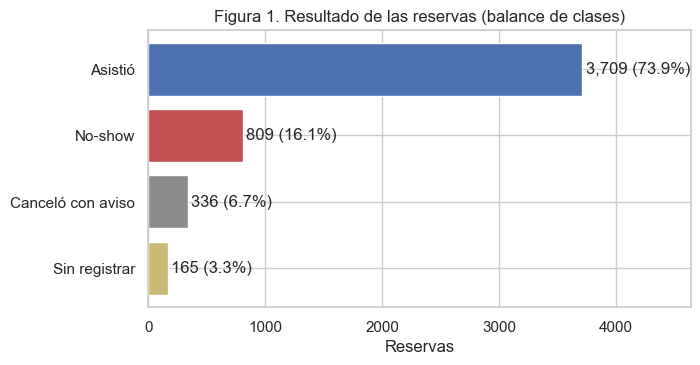

Entre reservas con resultado conocido: 17.9% no-show vs 82.1% asistencia.


In [10]:
mostrar(limpio[["anticipacion_horas", "reservas_activas", "capacidad", "reservas_previas", "inasistencias_previas", "duracion_min"]].describe().round(2))

balance = pd.Series(
    {
        "Asistió": int((sin_dup["asistencia"] == "present").sum()),
        "No-show": int((sin_dup["asistencia"] == "absent").sum()),
        "Canceló con aviso": int(canceladas.sum()),
        "Sin registrar": int(pendientes.sum()),
    }
)
fig, ax = plt.subplots(figsize=(7, 3.6))
colores = ["#4C72B0", "#C44E52", "#8C8C8C", "#CCB974"]
ax.barh(balance.index[::-1], balance.values[::-1], color=colores[::-1])
for i, v in enumerate(balance.values[::-1]):
    ax.text(v + 30, i, f"{v:,} ({v / balance.sum():.1%})", va="center")
ax.set_title("Figura 1. Resultado de las reservas (balance de clases)")
ax.set_xlabel("Reservas")
ax.set_xlim(0, balance.max() * 1.25)
guardar(fig, "fig01_balance_clases.png")
print(f"Entre reservas con resultado conocido: {limpio['no_show'].mean():.1%} no-show vs {1 - limpio['no_show'].mean():.1%} asistencia.")

**Conclusión (Figura 1):** la clase no-show es minoritaria (17,9 % de las reservas con resultado, 809 casos: muy por
encima del mínimo de 30 de la consigna). Un modelo que siempre diga "asistirá" tendría ~82 % de exactitud sin detectar
ningún no-show; por eso se eligen modelos por **PR-AUC**, el umbral se fija con **F2** y el árbol usa
`class_weight="balanced"`. En la regresión logística no se reponderan las clases: así su probabilidad queda calibrada y
recepción puede leerla como un porcentaje; el desbalance se compensa con el umbral. Las canceladas (6,7 %) y las
pendientes de registro (3,3 %) no tienen etiqueta y se excluyen del entrenamiento (sección 2.3).

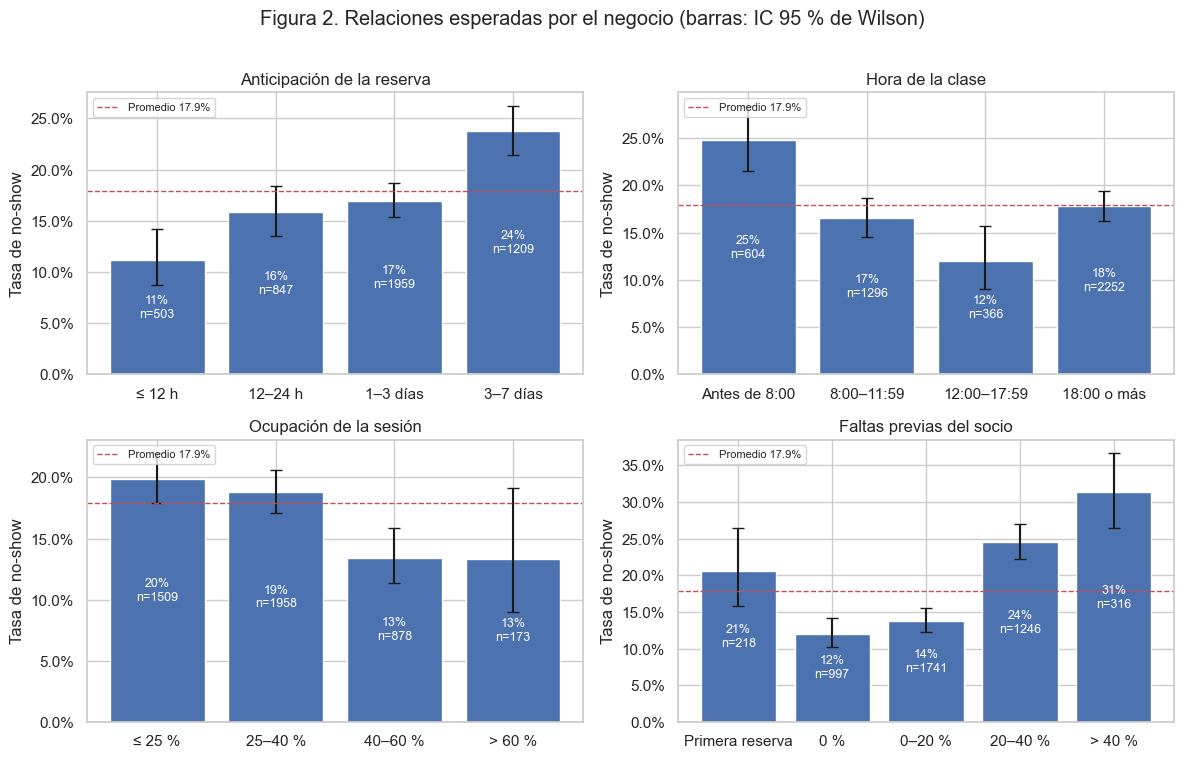

Anticipación de la reserva {'≤ 12 h': 0.111, '12–24 h': 0.158, '1–3 días': 0.169, '3–7 días': 0.237}
Hora de la clase {'Antes de 8:00': 0.248, '8:00–11:59': 0.165, '12:00–17:59': 0.12, '18:00 o más': 0.178}
Ocupación de la sesión {'≤ 25 %': 0.199, '25–40 %': 0.188, '40–60 %': 0.134, '> 60 %': 0.133}
Faltas previas del socio {'Primera reserva': 0.206, '0 %': 0.12, '0–20 %': 0.138, '20–40 %': 0.245, '> 40 %': 0.313}
Recordatorio {'Con recordatorio': 0.168, 'Sin recordatorio': 0.221}


In [11]:
def tasa_por(df, columna, etiquetas=None):
    g = df.groupby(columna, observed=True)["no_show"].agg(["mean", "size"])
    z = 1.96
    p, n = g["mean"], g["size"]
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    g["li"], g["ls"] = centro - margen, centro + margen  # intervalo de Wilson al 95 %
    if etiquetas:
        g.index = etiquetas
    return g


eda = limpio.assign(
    anticipacion=pd.cut(limpio["anticipacion_horas"], [0, 12, 24, 72, 168], labels=["≤ 12 h", "12–24 h", "1–3 días", "3–7 días"]),
    franja=pd.cut(limpio["hora_inicio"], [-1, 7, 11, 17, 23], labels=["Antes de 8:00", "8:00–11:59", "12:00–17:59", "18:00 o más"]),
    ocupacion=pd.cut(limpio["reservas_activas"] / limpio["capacidad"], [0, 0.25, 0.4, 0.6, 1.0], labels=["≤ 25 %", "25–40 %", "40–60 %", "> 60 %"]),
    recordatorio=limpio["recordatorio_enviado"].map({True: "Con recordatorio", False: "Sin recordatorio"}),
    historial=pd.cut(
        (limpio["inasistencias_previas"] / limpio["reservas_previas"].replace(0, np.nan)).fillna(-1),
        [-2, -0.5, 0.0001, 0.2, 0.4, 1.0],
        labels=["Primera reserva", "0 %", "0–20 %", "20–40 %", "> 40 %"],
    ),
)
paneles = [("anticipacion", "Anticipación de la reserva"), ("franja", "Hora de la clase"), ("ocupacion", "Ocupación de la sesión"), ("historial", "Faltas previas del socio")]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
base = limpio["no_show"].mean()
for ax, (col, titulo) in zip(axes.ravel(), paneles):
    g = tasa_por(eda, col)
    ax.bar(g.index.astype(str), g["mean"], yerr=[g["mean"] - g["li"], g["ls"] - g["mean"]], capsize=4, color="#4C72B0")
    ax.axhline(base, ls="--", color="#C44E52", lw=1, label=f"Promedio {base:.1%}")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m / 2, f"{m:.0%}\nn={n}", ha="center", color="white", fontsize=9)
    ax.set_title(titulo)
    ax.set_ylabel("Tasa de no-show")
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.legend(loc="upper left", fontsize=8)
fig.suptitle("Figura 2. Relaciones esperadas por el negocio (barras: IC 95 % de Wilson)", y=1.01)
fig.tight_layout()
guardar(fig, "fig02_relaciones_negocio.png")
for col, titulo in paneles + [("recordatorio", "Recordatorio")]:
    print(titulo, tasa_por(eda, col)["mean"].round(3).to_dict())

**Conclusión (Figura 2) — relaciones plausibles verificadas:**
1. **Más anticipación → más no-show**: quien reserva con días de antelación tiene más tiempo para cambiar de planes u
   olvidar; quien reserva el mismo día casi siempre asiste. Justifica `log_anticipacion` y `reserva_mismo_dia`.
2. **Clases antes de las 8:00 → más no-show**, coherente con la entrevista (horarios tempranos y socios que no avisan).
3. **Sesiones más llenas → menos no-show**: compromiso social y escasez del cupo. Justifica la variable `ocupacion`.
4. **El historial del socio es la señal más fuerte**: quien ya faltó a más del 40 % de sus reservas vuelve a faltar mucho
   más que el promedio; la primera reserva también tiene más riesgo. Justifica la tasa de inasistencia suavizada.
5. **Con recordatorio, menos no-show** (16,8 % vs. 22,1 % sin recordatorio, impreso arriba): respalda la HU07 del MVP.

Implicancia para el modelado: las relaciones son **monótonas pero moderadas** y con solapamiento entre grupos, así que se
espera un modelo útil pero lejos de la perfección (señal ni nula ni trivial).

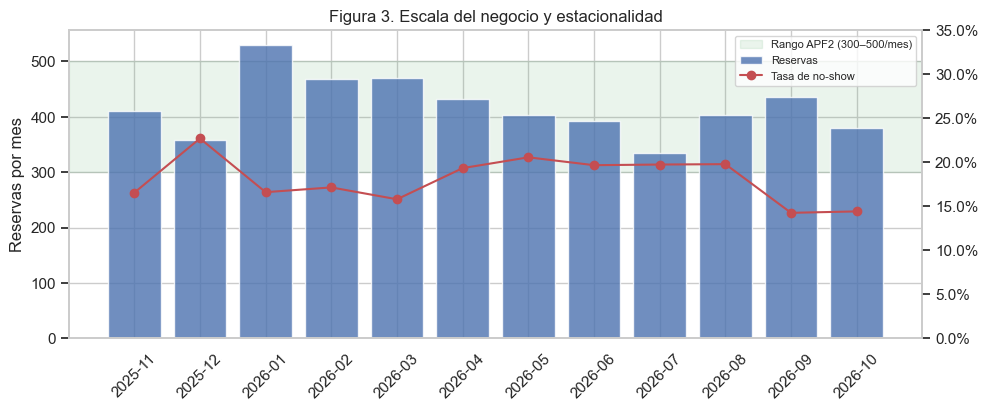

,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
reservas,411.000,358.000,530.000,469.000,471.000,432.000,403.000,393.000,335.000,403.000,435.000,379.000
tasa_no_show,0.165,0.227,0.166,0.171,0.158,0.193,0.206,0.197,0.197,0.198,0.142,0.144


In [12]:
mes = limpio["_inicio"].dt.tz_convert("America/Lima").dt.strftime("%Y-%m")
serie = pd.DataFrame(
    {
        "reservas": sin_dup.groupby(pd.to_datetime(sin_dup["inicio_sesion"], utc=True, format="ISO8601").dt.tz_convert("America/Lima").dt.strftime("%Y-%m")).size(),
        "tasa_no_show": limpio.groupby(mes)["no_show"].mean(),
    }
)
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.axhspan(300, 500, color="#55A868", alpha=0.12, label="Rango APF2 (300–500/mes)")
ax1.bar(serie.index, serie["reservas"], color="#4C72B0", alpha=0.8, label="Reservas")
ax1.set_ylabel("Reservas por mes")
ax2 = ax1.twinx()
ax2.plot(serie.index, serie["tasa_no_show"], color="#C44E52", marker="o", label="Tasa de no-show")
ax2.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax2.set_ylim(0, 0.35)
ax2.grid(False)
ax1.set_title("Figura 3. Escala del negocio y estacionalidad")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8)
ax1.tick_params(axis="x", rotation=45)
guardar(fig, "fig03_serie_mensual.png")
mostrar(serie.round(3).T)

**Conclusión (Figura 3):** el promedio mensual (≈ 420 reservas) está dentro del rango del Contrato de Datos (300–500);
solo enero (530) lo supera levemente por el verano, cuando suben las altas. La tasa de no-show **sube en diciembre (22,7 %)**
por las fiestas y es más baja en septiembre–octubre (≈ 14 %). Implicancia: hay estacionalidad, por lo que la partición debe
ser **cronológica** y el modelo incluye `temporada`. El periodo de prueba (agosto–octubre) tiene menos no-shows que el de
entrenamiento (14,7 % vs. 18,7 %) y no contiene diciembre: es una prueba exigente y el desempeño en fiestas queda por validar en PROY.

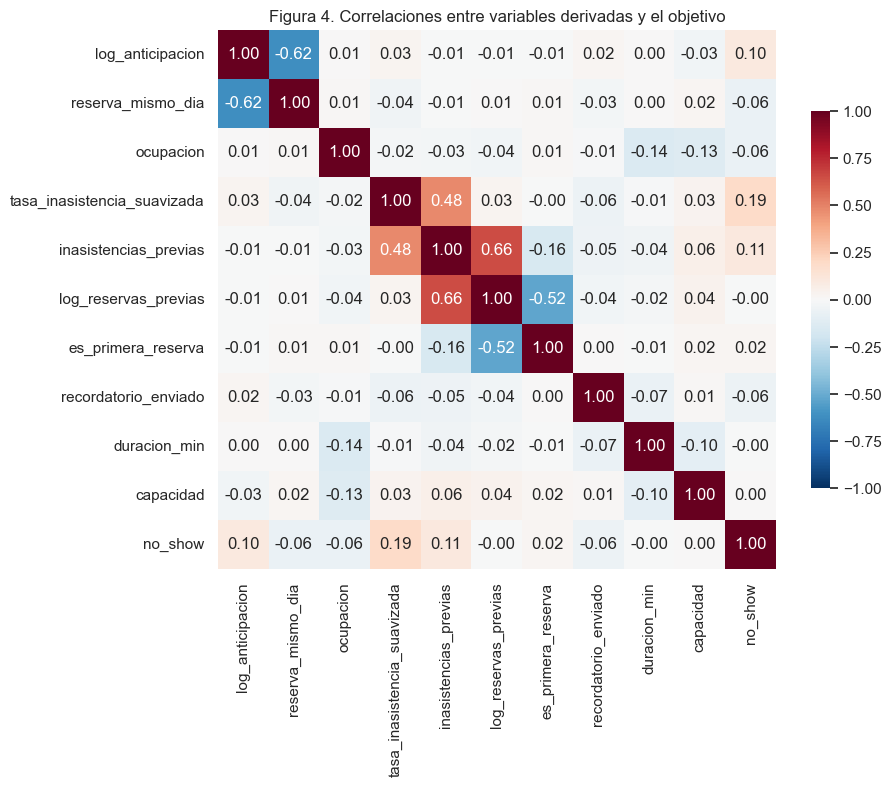

tasa_inasistencia_suavizada    0.188
inasistencias_previas          0.106
log_anticipacion               0.101
ocupacion                     -0.063
reserva_mismo_dia             -0.063
recordatorio_enviado          -0.055
es_primera_reserva             0.016
duracion_min                  -0.005
capacidad                      0.001
log_reservas_previas          -0.001


In [13]:
feats = tn.CaracteristicasNoShow().transform(limpio)
corr = feats[tn.VARIABLES_NUMERICAS].assign(no_show=limpio["no_show"]).corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Figura 4. Correlaciones entre variables derivadas y el objetivo")
guardar(fig, "fig04_correlaciones.png")
print(corr["no_show"].drop("no_show").sort_values(key=abs, ascending=False).round(3).to_string())

**Conclusión (Figura 4):** ninguna variable por sí sola explica el no-show (correlaciones individuales bajas, |r| < 0,2),
lo que descarta una separación trivial o fuga. Las más asociadas son el historial (`tasa_inasistencia_suavizada`,
`inasistencias_previas`) y la anticipación. Hay colinealidad esperable entre `inasistencias_previas`, la tasa suavizada y
`log_reservas_previas`, y entre `capacidad` y `duracion_min`: se maneja con **regularización L2** en la regresión logística y no
afecta a los árboles.

### 2.5 Ingeniería de características, partición y prevención de fuga
**Variables derivadas** (en `titan_noshow.CaracteristicasNoShow`, sin parámetros aprendidos):

| Variable | Justificación de negocio |
|---|---|
| `tasa_inasistencia_suavizada` = (faltas + 0,17·2) / (previas + 2) | El hábito del socio es el mejor predictor; el suavizado evita que 1 falta en 1 reserva parezca 100 %. El prior 0,17 es sectorial (no se estima con los datos → sin fuga). |
| `es_primera_reserva`, `log_reservas_previas` | Sin historial no hay compromiso demostrado; la experiencia reduce el riesgo con rendimientos decrecientes. |
| `log_anticipacion`, `reserva_mismo_dia` | Relación 1 del EDA, con efecto decreciente a mayor anticipación. |
| `ocupacion` = reservas_activas / capacidad | Relación 3 del EDA (sesiones llenas comprometen más). |
| `franja_horaria`, `dia_semana`, `temporada` | Horarios tempranos, lunes / viernes y fiestas concentran inasistencias. |

**Partición cronológica 80/20** (la misma proporción del Contrato de APF2): se ordena por `inicio_sesion` y el corte se hace
**entre sesiones**, nunca dentro de una misma clase. Una partición aleatoria mezclaría el futuro de un socio en el
entrenamiento y inflaría las métricas.

**Prevención de fuga de información:**

| Variable | Riesgo | Decisión |
|---|---|---|
| `estado`, `cancelada_en`, `asistencia` | Se conocen después de la clase o definen el objetivo | Excluidas (solo filtros de limpieza). |
| `reserva_id`, `sesion_id`, `socio_ref` | Identificadores: el modelo memorizaría socios | Excluidas; el historial del socio entra solo como conteos anteriores a la clase. |
| `reservas_previas`, `inasistencias_previas` | Podrían incluir la propia clase | La base de datos solo cuenta sesiones con inicio **anterior**; se verificó recalculándolo (regla de coherencia). |
| `reservas_activas` | Se mide al inicio de la clase | Se conoce antes del resultado; al predecir con más antelación se usa el valor del momento (documentado como limitación). |
| Imputación, escalado, one-hot | Ajustarlos con todo el dataset filtraría la prueba | Están dentro del `Pipeline` y se ajustan solo con entrenamiento (y con cada pliegue en la validación cruzada). |
| `instructor`, `clase` | 1:1 con `disciplina` en la agenda de TITAN GYM | Excluidas (redundantes y minimización de datos personales del personal). |

In [14]:
sesiones = limpio.drop_duplicates("sesion_id")[["sesion_id", "_inicio"]].sort_values("_inicio")
acumulado = limpio.groupby("sesion_id").size().reindex(sesiones["sesion_id"]).cumsum() / len(limpio)
sesion_corte = acumulado[acumulado >= 0.80].index[0]
inicio_corte = sesiones.set_index("sesion_id").loc[sesion_corte, "_inicio"]
es_train = limpio["_inicio"] <= inicio_corte

X = limpio[tn.CAMPOS_ENTRADA]
y = limpio["no_show"]
X_train, y_train = X[es_train], y[es_train]
X_test, y_test = X[~es_train], y[~es_train]
particion = pd.DataFrame(
    {
        "conjunto": ["Entrenamiento", "Prueba"],
        "desde": [limpio.loc[es_train, "_inicio"].min().date(), limpio.loc[~es_train, "_inicio"].min().date()],
        "hasta": [limpio.loc[es_train, "_inicio"].max().date(), limpio.loc[~es_train, "_inicio"].max().date()],
        "filas": [len(X_train), len(X_test)],
        "proporción": [len(X_train) / len(X), len(X_test) / len(X)],
        "no_shows": [int(y_train.sum()), int(y_test.sum())],
        "tasa_no_show": [y_train.mean(), y_test.mean()],
    }
)
mostrar(particion.round(3))
assert set(limpio.loc[es_train, "sesion_id"]).isdisjoint(limpio.loc[~es_train, "sesion_id"]), "Una sesión quedó partida"

,conjunto,desde,hasta,filas,proporción,no_shows,tasa_no_show
0,Entrenamiento,2025-11-03,2026-08-17,3621,0.801,677,0.187
1,Prueba,2026-08-18,2026-10-31,897,0.199,132,0.147


**Calidad y limitaciones del dataset:** (1) es simulado: la fuerza de cada relación la fijó el equipo con supuestos
sectoriales, así que las métricas **no** prueban que el modelo acierte con socios reales; (2) la cobertura de registro de
asistencia (~96,5 %) deja fuera reservas sin etiqueta; si en producción recepción no marca la asistencia, el dataset se sesga
hacia los socios más visibles; (3) no hay variables externas (clima, pagos, membresía). En producción se mejoran exportando
`admin_dataset()` cada mes, exigiendo el registro de asistencia en cada clase (retroalimentación del docente en APF2) y
reentrenando con datos reales.

## 3. Paso 3 — Modelado, entrenamiento y comparación
### 3.1 Líneas base
* **Dummy "todos asisten"** (`most_frequent`): es la situación actual de la MiPYME, que no anticipa ningún no-show.
* **Dummy estratificado**: adivina al azar respetando la proporción de clases.
* **Regla de riesgo del MVP** (`src/features/admin/risk.ts`): suma puntos por faltas previas, primera reserva, > 72 h de
  anticipación y clase antes de las 8:00. Se evalúa "alto" como positivo (y "medio o alto" como variante).

### 3.2 Modelos de la Unidad 3 y búsqueda de hiperparámetros
Todos usan **el mismo pipeline** (características → imputación → escalado/one-hot → modelo) y la **misma validación cruzada
temporal** (`TimeSeriesSplit`, 5 pliegues, solo dentro del entrenamiento). Métrica de selección: **PR-AUC** de la clase no-show.

| Modelo | Por qué se prueba | Control de sobreajuste | Espacio de búsqueda |
|---|---|---|---|
| Regresión logística | Interpretable (odds ratios), liviana, buena con relaciones monótonas | Regularización L2 (`C`) | C ∈ {0.003, 0.01, 0.03, 0.1, 0.3, 1, 3} |
| KNN | No paramétrico; requiere escalado (incluido) | Número de vecinos | k ∈ {25, 51, 101, 201}, pesos ∈ {uniforme, distancia} |
| Árbol de decisión | Reglas legibles para recepción | Profundidad máxima y hojas mínimas | max_depth ∈ {2, 3, 4, 5, 6, 8}, min_samples_leaf ∈ {20, 50, 100} |
| Gradient Boosting | Captura interacciones y no linealidades (semana 14) | Tasa de aprendizaje, profundidad, submuestreo 0,8 | n_estimators ∈ {100, 200, 400}, learning_rate ∈ {0.02, 0.05, 0.1}, max_depth ∈ {2, 3} |

**Regla de selección (definida antes de mirar la prueba):** gana el mayor PR-AUC medio en validación cruzada; si otro modelo
está a menos de 0,01 del mejor, se prefiere el más interpretable y liviano (logística > árbol > KNN > boosting), porque lo
usará personal no técnico y debe correr gratis dentro del MVP.

In [15]:
cv = TimeSeriesSplit(n_splits=5)
candidatos = {
    "Regresión logística": (
        LogisticRegression(max_iter=5000, random_state=SEED),  # sin class_weight: probabilidad calibrada
        {"modelo__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"modelo__n_neighbors": [25, 51, 101, 201], "modelo__weights": ["uniform", "distance"]},
    ),
    "Árbol de decisión": (
        DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"modelo__max_depth": [2, 3, 4, 5, 6, 8], "modelo__min_samples_leaf": [20, 50, 100]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(subsample=0.8, random_state=SEED),
        {"modelo__n_estimators": [100, 200, 400], "modelo__learning_rate": [0.02, 0.05, 0.1], "modelo__max_depth": [2, 3]},
    ),
}
ORDEN_SIMPLICIDAD = list(candidatos)

busquedas, filas_cv = {}, []
for nombre, (estimador, grilla) in candidatos.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(
        tn.construir_pipeline(estimador),
        grilla,
        scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
        refit="pr_auc",
        cv=cv,
        n_jobs=1,
        return_train_score=True,
    )
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    i = gs.best_index_
    r = gs.cv_results_
    filas_cv.append(
        {
            "modelo": nombre,
            "mejores_hiperparámetros": {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()},
            "PR-AUC train": r["mean_train_pr_auc"][i],
            "PR-AUC CV": r["mean_test_pr_auc"][i],
            "PR-AUC CV (desv.)": r["std_test_pr_auc"][i],
            "ROC-AUC CV": r["mean_test_roc_auc"][i],
            "brecha train−CV": r["mean_train_pr_auc"][i] - r["mean_test_pr_auc"][i],
            "segundos": time.perf_counter() - t0,
        }
    )
tabla_cv = pd.DataFrame(filas_cv)
mostrar(tabla_cv.round(3))
print(f"Tasa base de no-show en entrenamiento (PR-AUC de un modelo al azar): {y_train.mean():.3f}")

,modelo,mejores_hiperparámetros,PR-AUC train,PR-AUC CV,PR-AUC CV (desv.),ROC-AUC CV,brecha train−CV,segundos
0,Regresión logística,{'C': 0.03},0.299,0.315,0.052,0.650,-0.016,1.357
1,KNN,"{'n_neighbors': 201, 'weights': 'distance'}",1.000,0.275,0.033,0.633,0.725,4.205
2,Árbol de decisión,"{'max_depth': 8, 'min_samples_leaf': 50}",0.329,0.253,0.027,0.608,0.076,3.226
3,Gradient Boosting,"{'learning_rate': 0.02, 'max_depth': 2, 'n_est...",0.390,0.270,0.050,0.628,0.120,38.136


Tasa base de no-show en entrenamiento (PR-AUC de un modelo al azar): 0.187


### 3.3 Control de sobreajuste
La tabla anterior compara PR-AUC en entrenamiento y en validación. Además se grafica cómo cambia la brecha con la
complejidad de cada familia (profundidad del árbol, número de vecinos, regularización y tamaño del boosting).

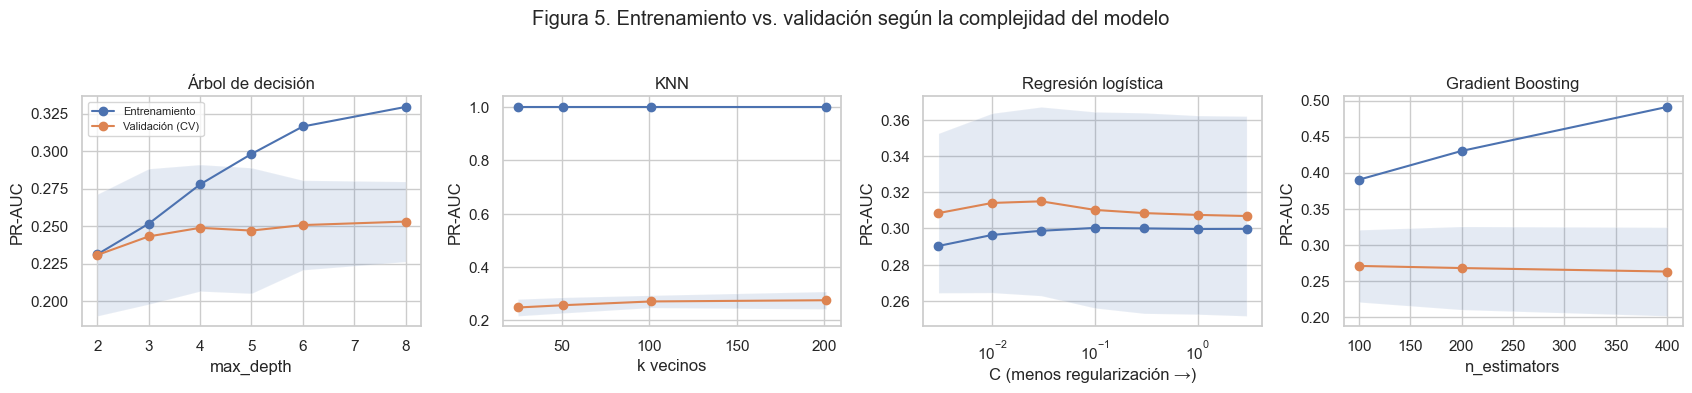

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
curvas = [
    ("Árbol de decisión", "param_modelo__max_depth", {"param_modelo__min_samples_leaf": busquedas["Árbol de decisión"].best_params_["modelo__min_samples_leaf"]}, "max_depth"),
    ("KNN", "param_modelo__n_neighbors", {"param_modelo__weights": busquedas["KNN"].best_params_["modelo__weights"]}, "k vecinos"),
    ("Regresión logística", "param_modelo__C", {}, "C (menos regularización →)"),
    ("Gradient Boosting", "param_modelo__n_estimators", {"param_modelo__learning_rate": busquedas["Gradient Boosting"].best_params_["modelo__learning_rate"], "param_modelo__max_depth": busquedas["Gradient Boosting"].best_params_["modelo__max_depth"]}, "n_estimators"),
]
for ax, (nombre, param, fijos, etiqueta) in zip(axes, curvas):
    r = pd.DataFrame(busquedas[nombre].cv_results_)
    for k, v in fijos.items():
        r = r[r[k] == v]
    r = r.sort_values(param)
    xs = r[param].astype(float)
    ax.plot(xs, r["mean_train_pr_auc"], marker="o", label="Entrenamiento")
    ax.plot(xs, r["mean_test_pr_auc"], marker="o", label="Validación (CV)")
    ax.fill_between(xs, r["mean_test_pr_auc"] - r["std_test_pr_auc"], r["mean_test_pr_auc"] + r["std_test_pr_auc"], alpha=0.15)
    if nombre == "Regresión logística":
        ax.set_xscale("log")
    ax.set_title(nombre)
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("PR-AUC")
axes[0].legend(fontsize=8)
fig.suptitle("Figura 5. Entrenamiento vs. validación según la complejidad del modelo", y=1.03)
fig.tight_layout()
guardar(fig, "fig05_sobreajuste.png")

**Conclusión (Figura 5 y tabla de validación):**
* **Gradient Boosting** sube en entrenamiento al agregar árboles (PR-AUC ≈ 0,39 → 0,49) mientras la validación baja
  levemente: sobreajusta. Por eso la búsqueda se queda con el modelo más pequeño (100 árboles, profundidad 2, tasa 0,02).
* **Árbol de decisión**: el entrenamiento crece con la profundidad (≈ 0,23 → 0,33) pero la validación queda plana en ≈ 0,25
  desde profundidad 4; la hoja mínima de 50 reservas es lo que contiene su sobreajuste.
* **KNN** con pesos por distancia memoriza el entrenamiento (PR-AUC 1,0, brecha ≈ 0,73); su validación solo mejora con
  muchos vecinos (k = 201), señal de que necesita suavizar mucho para generalizar.
* **Regresión logística** no sobreajusta: entrenamiento y validación quedan a la par en todo el rango de C (brecha ≈ 0) y la
  regularización C = 0,03 da el mejor promedio. Su validación incluso supera al entrenamiento porque los pliegues temporales
  más recientes tienen más historial por socio, y por eso son más fáciles de predecir.

### 3.4 Selección del modelo y umbral de decisión
Los umbrales se eligen con predicciones **fuera de pliegue** del entrenamiento (cada pliegue temporal predice reservas que el
modelo no vio), nunca con la prueba:
* **Umbral de contacto** (riesgo medio o alto): maximiza **F2** con la restricción operativa de marcar como máximo el 40 % de las reservas. Es la decisión binaria que se evalúa.
* **Umbral alto**: el percentil 85 de las probabilidades fuera de pliegue (el 15 % de mayor riesgo), para reservar la confirmación obligatoria a los casos más probables.

In [17]:
mejor_cv = tabla_cv["PR-AUC CV"].max()
empatados = tabla_cv[tabla_cv["PR-AUC CV"] >= mejor_cv - 0.01]["modelo"].tolist()
seleccionado = min(empatados, key=ORDEN_SIMPLICIDAD.index)
print(f"Mejor PR-AUC CV: {mejor_cv:.3f} · modelos a menos de 0,01: {empatados} → seleccionado: {seleccionado}")


def predicciones_fuera_de_pliegue(pipeline, X, y):
    proba = pd.Series(np.nan, index=X.index)
    for tr, va in cv.split(X):
        m = clone(pipeline).fit(X.iloc[tr], y.iloc[tr])
        proba.iloc[va] = m.predict_proba(X.iloc[va])[:, 1]
    mascara = proba.notna()
    return proba[mascara], y[mascara]


def elegir_umbral(proba, y_real, tope=TOPE_MARCADAS):
    mejores = (-1, 0.5)
    for u in np.unique(np.round(proba, 4)):
        pred = proba >= u
        if pred.mean() > tope:
            continue
        f2 = fbeta_score(y_real, pred, beta=2, zero_division=0)
        if f2 > mejores[0]:
            mejores = (f2, float(u))
    return mejores[1]


umbrales = {}
for nombre, gs in busquedas.items():
    p_oof, y_oof = predicciones_fuera_de_pliegue(gs.best_estimator_, X_train, y_train)
    umbrales[nombre] = elegir_umbral(p_oof.to_numpy(), y_oof.to_numpy())
    if nombre == seleccionado:
        umbral_alto = float(np.quantile(p_oof, 0.85))
        alto_oof = p_oof >= umbral_alto
        print(f"Umbral alto (percentil 85) = {umbral_alto:.3f} → precisión {precision_score(y_oof, alto_oof):.3f}, recall {recall_score(y_oof, alto_oof):.3f}")
        pred_oof = p_oof >= umbrales[nombre]
        print(
            f"{nombre}: umbral de contacto = {umbrales[nombre]:.3f} · en validación fuera de pliegue → recall {recall_score(y_oof, pred_oof):.3f}, "
            f"precisión {precision_score(y_oof, pred_oof):.3f}, marcadas {pred_oof.mean():.1%}"
        )
print("Umbrales por modelo:", {k: round(v, 3) for k, v in umbrales.items()})
modelo_final = busquedas[seleccionado].best_estimator_

Mejor PR-AUC CV: 0.315 · modelos a menos de 0,01: ['Regresión logística'] → seleccionado: Regresión logística


Umbral alto (percentil 85) = 0.268 → precisión 0.364, recall 0.291
Regresión logística: umbral de contacto = 0.193 · en validación fuera de pliegue → recall 0.580, precisión 0.275, marcadas 39.7%


Umbrales por modelo: {'Regresión logística': 0.193, 'KNN': 0.189, 'Árbol de decisión': 0.526, 'Gradient Boosting': 0.193}


### 3.5 Viabilidad de despliegue
Se mide el tamaño del modelo exportado y el tiempo de predicción por reserva. El servicio donde se integra es el MVP:
frontend en **Vercel (plan gratuito)** y base de datos en **Supabase (plan gratuito)**. Ver la sección 6.

In [18]:
ruta_modelo = MODELO / "modelo_noshow_titan.joblib"
joblib.dump(modelo_final, ruta_modelo)
registro = X_test.iloc[[0]]
t0 = time.perf_counter()
for _ in range(200):
    modelo_final.predict_proba(registro)
latencia_ms = (time.perf_counter() - t0) / 200 * 1000
t0 = time.perf_counter()
modelo_final.predict_proba(X_test)
lote_ms = (time.perf_counter() - t0) * 1000
print(f"Tamaño del modelo: {ruta_modelo.stat().st_size / 1024:.1f} KB · latencia por reserva: {latencia_ms:.2f} ms · {len(X_test)} reservas en {lote_ms:.0f} ms")

Tamaño del modelo: 6.5 KB · latencia por reserva: 6.27 ms · 897 reservas en 8 ms


## 4. Paso 4 — Evaluación en el conjunto de prueba (se usa una sola vez)
La selección del modelo y del umbral ya quedó fijada. Recién ahora se evalúa en la prueba (agosto–octubre 2026); se muestran
todos los modelos y las líneas base **solo como referencia**, sin volver a elegir.

In [19]:
def metricas(nombre, y_real, pred, score):
    return {
        "modelo": nombre,
        "accuracy": accuracy_score(y_real, pred),
        "precision": precision_score(y_real, pred, zero_division=0),
        "recall": recall_score(y_real, pred, zero_division=0),
        "F1": f1_score(y_real, pred, zero_division=0),
        "F2": fbeta_score(y_real, pred, beta=2, zero_division=0),
        "PR-AUC": average_precision_score(y_real, score),
        "ROC-AUC": roc_auc_score(y_real, score) if np.std(score) > 0 else 0.5,
        "% marcadas": np.mean(pred),
    }


filas = []
for nombre, estrategia in [("Dummy: todos asisten (situación actual)", "most_frequent"), ("Dummy: estratificado", "stratified")]:
    d = DummyClassifier(strategy=estrategia, random_state=SEED).fit(X_train, y_train)
    filas.append(metricas(nombre, y_test, d.predict(X_test), d.predict_proba(X_test)[:, 1]))
puntos = tn.puntos_regla_mvp(X_test)
nivel = tn.regla_mvp(X_test)
filas.append(metricas("Regla del MVP: riesgo alto", y_test, nivel == "alto", puntos))
filas.append(metricas("Regla del MVP: riesgo medio o alto", y_test, nivel != "bajo", puntos))
probas_test = {}
for nombre, gs in busquedas.items():
    probas_test[nombre] = gs.best_estimator_.predict_proba(X_test)[:, 1]
    filas.append(metricas(nombre + (" ★ seleccionado" if nombre == seleccionado else ""), y_test, probas_test[nombre] >= umbrales[nombre], probas_test[nombre]))
    if nombre == seleccionado:
        filas.append(metricas(nombre + ": solo riesgo alto", y_test, probas_test[nombre] >= umbral_alto, probas_test[nombre]))
tabla_test = pd.DataFrame(filas).set_index("modelo")
tabla_test.to_csv(MODELO / "metricas_prueba.csv")
mostrar(tabla_test.round(3))

,accuracy,precision,recall,F1,F2,PR-AUC,ROC-AUC,% marcadas
modelo,,,,,,,,
Dummy: todos asisten (situación actual),0.853,0.000,0.000,0.000,0.000,0.147,0.500,0.000
Dummy: estratificado,0.716,0.145,0.189,0.164,0.178,0.147,0.498,0.193
Regla del MVP: riesgo alto,0.800,0.318,0.311,0.314,0.312,0.230,0.647,0.144
Regla del MVP: riesgo medio o alto,0.657,0.228,0.561,0.325,0.434,0.230,0.647,0.361
Regresión logística ★ seleccionado,0.637,0.243,0.697,0.361,0.508,0.319,0.721,0.421
Regresión logística: solo riesgo alto,0.778,0.311,0.417,0.356,0.390,0.319,0.721,0.197
KNN,0.632,0.245,0.720,0.365,0.519,0.295,0.720,0.433
Árbol de decisión,0.591,0.206,0.621,0.309,0.442,0.238,0.669,0.445
Gradient Boosting,0.676,0.255,0.629,0.363,0.487,0.310,0.710,0.362


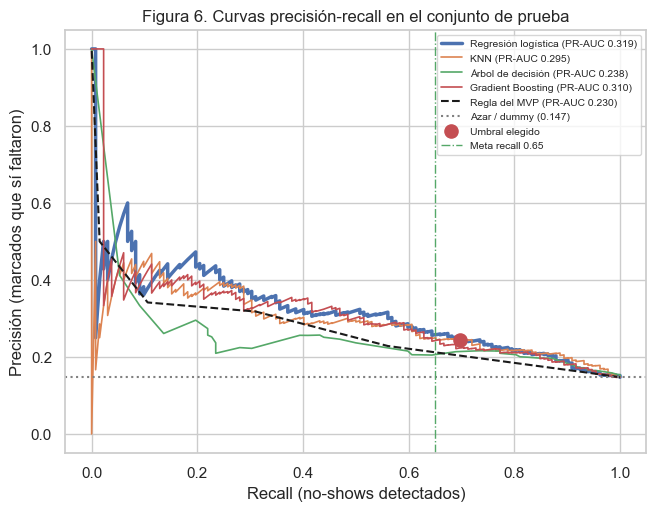

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for nombre, proba in probas_test.items():
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, lw=2.5 if nombre == seleccionado else 1.2, label=f"{nombre} (PR-AUC {average_precision_score(y_test, proba):.3f})")
p, r, _ = precision_recall_curve(y_test, puntos)
ax.plot(r, p, ls="--", color="k", label=f"Regla del MVP (PR-AUC {average_precision_score(y_test, puntos):.3f})")
ax.axhline(y_test.mean(), color="gray", ls=":", label=f"Azar / dummy ({y_test.mean():.3f})")
sel = tabla_test.loc[seleccionado + " ★ seleccionado"]
ax.scatter(sel["recall"], sel["precision"], s=90, color="#C44E52", zorder=5, label="Umbral elegido")
ax.axvline(META_RECALL, color="#55A868", ls="-.", lw=1, label=f"Meta recall {META_RECALL}")
ax.set_xlabel("Recall (no-shows detectados)")
ax.set_ylabel("Precisión (marcados que sí faltaron)")
ax.set_title("Figura 6. Curvas precisión-recall en el conjunto de prueba")
ax.legend(fontsize=7.5, loc="upper right")
guardar(fig, "fig06_curvas_pr.png")

### 4.1 Análisis de errores

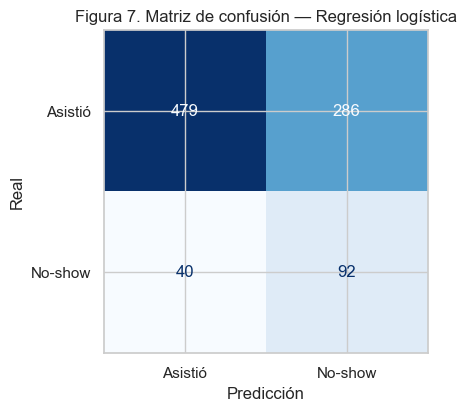

Calibración: probabilidad media predicha 0.198 vs. tasa real 0.147 · Brier 0.1175 (dummy con la tasa de entrenamiento: 0.1271)
VP=92 (no-shows detectados) · FN=40 (no-shows no detectados) · FP=286 (confirmaciones innecesarias) · VN=479

No-shows que el modelo NO detectó (probabilidad más baja):


,disciplina,dia_semana,hora_inicio,anticipacion_horas,reservas_activas,capacidad,reservas_previas,inasistencias_previas,recordatorio_enviado,no_show,probabilidad,regla_mvp
3952,Cross Training,6,10,58.6,10,16,11,0,True,1,0.074,bajo
3631,Yoga,2,17,42.7,5,15,4,0,True,1,0.080,bajo
3725,Yoga,2,17,14.1,3,15,9,1,True,1,0.080,bajo


Reservas marcadas como riesgo que SÍ asistieron (probabilidad más alta):


,disciplina,dia_semana,hora_inicio,anticipacion_horas,reservas_activas,capacidad,reservas_previas,inasistencias_previas,recordatorio_enviado,no_show,probabilidad,regla_mvp
4404,HIIT,3,19,83.1,5,20,13,11,False,0,0.719,alto
3718,Zumba,2,8,56.1,11,30,7,7,False,0,0.685,alto
4020,Cross Training,4,19,86.7,9,16,10,9,False,0,0.672,alto


In [21]:
proba_sel = probas_test[seleccionado]
pred_sel = proba_sel >= umbrales[seleccionado]
fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_sel), display_labels=["Asistió", "No-show"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Figura 7. Matriz de confusión — {seleccionado}")
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
guardar(fig, "fig07_matriz_confusion.png")
vn, fp, fn, vp = confusion_matrix(y_test, pred_sel).ravel()
print(
    f"Calibración: probabilidad media predicha {proba_sel.mean():.3f} vs. tasa real {y_test.mean():.3f} · "
    f"Brier {brier_score_loss(y_test, proba_sel):.4f} (dummy con la tasa de entrenamiento: {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f})"
)
print(f"VP={vp} (no-shows detectados) · FN={fn} (no-shows no detectados) · FP={fp} (confirmaciones innecesarias) · VN={vn}")

casos = limpio.loc[~es_train].assign(probabilidad=proba_sel, prediccion=pred_sel.astype(int), regla_mvp=nivel)
cols_caso = ["disciplina", "dia_semana", "hora_inicio", "anticipacion_horas", "reservas_activas", "capacidad", "reservas_previas", "inasistencias_previas", "recordatorio_enviado", "no_show", "probabilidad", "regla_mvp"]
falsos_negativos = casos[(casos["no_show"] == 1) & (casos["prediccion"] == 0)].nsmallest(3, "probabilidad")
falsos_positivos = casos[(casos["no_show"] == 0) & (casos["prediccion"] == 1)].nlargest(3, "probabilidad")
print("\nNo-shows que el modelo NO detectó (probabilidad más baja):")
mostrar(falsos_negativos[cols_caso].round(3))
print("Reservas marcadas como riesgo que SÍ asistieron (probabilidad más alta):")
mostrar(falsos_positivos[cols_caso].round(3))

**Hipótesis sobre los fallos (6 casos de las tablas anteriores):**
* **No-shows no detectados** (probabilidad ≈ 7–8 %): un Cross Training del sábado a las 10:00 y dos Yoga del martes a las
  17:00, de socios con historial casi limpio (0–1 faltas en 4–11 reservas) y con recordatorio. Todo lo que el MVP registra
  indica bajo riesgo: sábado, tarde y yoga son las franjas con menos inasistencias. La falta se explica por imprevistos que el
  MVP no captura (trabajo, salud, tráfico) o por un cambio en el hábito del socio que el historial todavía no refleja.
  Ninguna variable disponible los anticipa; se mitigan con la lista de espera, no con el modelo.
* **Falsas alarmas** (probabilidad ≈ 67–72 %): socios con muchas faltas previas (11 de 13, 7 de 7 y 9 de 10), sin
  recordatorio y que reservaron con 2–4 días de anticipación, pero esta vez sí asistieron. El hábito pesa, pero no es
  determinista; para recepción el costo es solo un mensaje de confirmación, coherente con priorizar recall. La regla del MVP
  también los marcaba como riesgo alto.
* El dataset es simulado: estos patrones reflejan el mecanismo generador y deben revisarse con casos reales en PROY.
* **Calibración:** el modelo predice en promedio 19,8 % de no-show y en la prueba ocurrió 14,7 %, porque la tasa bajó entre
  el entrenamiento y la prueba. Aun así su error de Brier (0,1175) es menor que el de predecir siempre la tasa histórica
  (0,1271). En PROY conviene reentrenar o recalibrar periódicamente con datos recientes.

### 4.2 Interpretación: importancia de variables

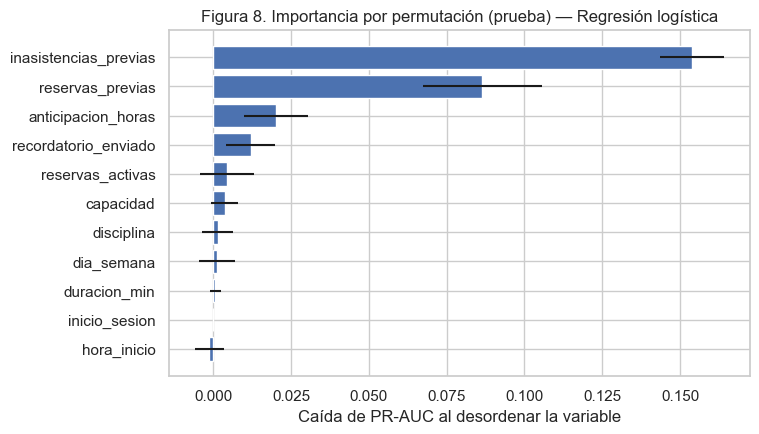

,variable,caida_PR_AUC,desv
9,inasistencias_previas,0.1538,0.0101
8,reservas_previas,0.0865,0.0191
7,anticipacion_horas,0.0200,0.0103
10,recordatorio_enviado,0.0121,0.0079
6,reservas_activas,0.0044,0.0087
5,capacidad,0.0037,0.0042
0,disciplina,0.0015,0.0049
2,dia_semana,0.0011,0.0058
4,duracion_min,0.0007,0.0018
1,inicio_sesion,0.0000,0.0000


Coeficientes (variables numéricas estandarizadas: efecto de +1 desviación estándar):


,variable,coeficiente,odds_ratio
3,tasa_inasistencia_suavizada,0.342,1.408
0,log_anticipacion,0.268,1.307
14,disciplina_Yoga,-0.191,0.826
18,franja_horaria_tarde,-0.191,0.826
25,dia_semana_6,-0.183,0.833
19,franja_horaria_temprano,0.167,1.182
11,disciplina_Funcional,0.167,1.182
20,dia_semana_1,0.142,1.153
2,ocupacion,-0.141,0.868
7,recordatorio_enviado,-0.133,0.876


In [22]:
importancia = permutation_importance(modelo_final, X_test, y_test, scoring="average_precision", n_repeats=20, random_state=SEED, n_jobs=1)
tabla_imp = pd.DataFrame({"variable": tn.CAMPOS_ENTRADA, "caida_PR_AUC": importancia.importances_mean, "desv": importancia.importances_std}).sort_values("caida_PR_AUC", ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(tabla_imp["variable"][::-1], tabla_imp["caida_PR_AUC"][::-1], xerr=tabla_imp["desv"][::-1], color="#4C72B0")
ax.set_xlabel("Caída de PR-AUC al desordenar la variable")
ax.set_title(f"Figura 8. Importancia por permutación (prueba) — {seleccionado}")
guardar(fig, "fig08_importancia.png")
mostrar(tabla_imp.round(4))

if seleccionado == "Regresión logística":
    nombres = modelo_final.named_steps["preprocesamiento"].get_feature_names_out()
    coef = modelo_final.named_steps["modelo"].coef_[0]
    tabla_coef = pd.DataFrame({"variable": nombres, "coeficiente": coef, "odds_ratio": np.exp(coef)}).sort_values("coeficiente", key=abs, ascending=False)
    print("Coeficientes (variables numéricas estandarizadas: efecto de +1 desviación estándar):")
    mostrar(tabla_coef.round(3).head(15))

**Lectura de la importancia y acciones que sugiere cada hallazgo:**
* **Historial de faltas** (`inasistencias_previas` y `reservas_previas`: al desordenarlas el PR-AUC cae ≈ 0,15 y ≈ 0,09; en
  la regresión logística, +1 desviación de la tasa de inasistencia multiplica las odds de no-show por ≈ 1,4) → confirmación
  obligatoria por WhatsApp hasta 3 h antes para los reincidentes (riesgo alto).
* **Anticipación** (odds × ≈ 1,3 por desviación) → para reservas hechas con más de 3 días, un segundo recordatorio 24 h antes.
* **Recordatorio enviado** (odds × ≈ 0,88) → mantener el recordatorio activado por defecto e invitar a reactivarlo a quien lo desactivó.
* **Ocupación y horario** (efecto menor en la prueba: odds × ≈ 0,87 por desviación de ocupación; franja temprana y lunes
  suben el riesgo, yoga, tarde y sábado lo bajan) → en clases tempranas con baja ocupación, abrir la lista de espera o
  permitir 1–2 cupos de sobre-reserva controlada.
* `inicio_sesion` (temporada) no aporta en la prueba porque agosto–octubre es temporada regular; se mantiene para diciembre y verano.

### 4.3 Traducción a valor de negocio (periodo de prueba)

In [23]:
semanas = (limpio.loc[~es_train, "_inicio"].max() - limpio.loc[~es_train, "_inicio"].min()).days / 7
tasa_actual = y_test.mean()
filas_imp = []
for conversion in (0.2, 0.3, 0.4):  # SUPUESTO: fracción de no-shows detectados que una confirmación evita
    evitados = vp * conversion
    filas_imp.append(
        {
            "supuesto_conversion": f"{conversion:.0%}",
            "no_shows_evitados_por_semana": evitados / semanas,
            "tasa_no_show_proyectada": (y_test.sum() - evitados) / len(y_test),
            "cupos_recuperados_por_mes": evitados / semanas * 4.33,
            "valor_recuperado_soles_mes": evitados / semanas * 4.33 * VALOR_CUPO_SOLES,
        }
    )
impacto = pd.DataFrame(filas_imp)
print(f"Periodo de prueba: {semanas:.1f} semanas · {len(y_test)} reservas · tasa de no-show actual {tasa_actual:.1%}")
print(f"Reservas a confirmar por semana: {pred_sel.sum() / semanas:.1f} (≈ {pred_sel.sum() / semanas * MINUTOS_POR_CONFIRMACION:.0f} min de recepción)")
print(f"No-shows por semana: {y_test.sum() / semanas:.1f} · detectados por el modelo: {vp / semanas:.1f} ({vp / y_test.sum():.0%})")
print(f"Lift: entre las reservas marcadas, la tasa de no-show es {vp / max(pred_sel.sum(), 1):.1%} ({vp / max(pred_sel.sum(), 1) / tasa_actual:.1f}× el promedio)")
mostrar(impacto.round(3))
cumple_recall = sel["recall"] >= META_RECALL
cumple_tope = sel["% marcadas"] <= TOPE_MARCADAS
supera_regla = sel["PR-AUC"] > tabla_test.loc["Regla del MVP: riesgo alto", "PR-AUC"] and sel["F2"] > tabla_test.loc["Regla del MVP: riesgo alto", "F2"]
print(f"\nMeta de recall (≥ {META_RECALL}): {'CUMPLIDA' if cumple_recall else 'NO CUMPLIDA'} (recall {sel['recall']:.3f})")
print(f"Tope operativo (≤ {TOPE_MARCADAS:.0%} de reservas contactadas): {'CUMPLIDO' if cumple_tope else 'EXCEDIDO'} ({sel['% marcadas']:.1%})")
print(f"Meta del PROY (tasa < {META_TASA_PROY:.0%}) en el escenario conservador (20 %): {'alcanzable' if impacto.loc[0, 'tasa_no_show_proyectada'] < META_TASA_PROY else 'no alcanzable'} ({impacto.loc[0, 'tasa_no_show_proyectada']:.1%}, supuesto)")
print(f"Supera a la regla del MVP en PR-AUC y F2: {'SÍ' if supera_regla else 'NO'}")

Periodo de prueba: 10.6 semanas · 897 reservas · tasa de no-show actual 14.7%
Reservas a confirmar por semana: 35.8 (≈ 72 min de recepción)
No-shows por semana: 12.5 · detectados por el modelo: 8.7 (70%)
Lift: entre las reservas marcadas, la tasa de no-show es 24.3% (1.7× el promedio)


,supuesto_conversion,no_shows_evitados_por_semana,tasa_no_show_proyectada,cupos_recuperados_por_mes,valor_recuperado_soles_mes
0,20%,1.741,0.127,7.537,75.365
1,30%,2.611,0.116,11.305,113.048
2,40%,3.481,0.106,15.073,150.731



Meta de recall (≥ 0.65): CUMPLIDA (recall 0.697)
Tope operativo (≤ 40% de reservas contactadas): EXCEDIDO (42.1%)
Meta del PROY (tasa < 13%) en el escenario conservador (20 %): alcanzable (12.7%, supuesto)
Supera a la regla del MVP en PR-AUC y F2: SÍ


**Lectura para el administrador (sin tecnicismos):** el modelo **no adivina** quién faltará; ordena las reservas de cada
clase de mayor a menor riesgo. Si recepción confirma solo a las marcadas, concentra su esfuerzo donde ocurren la mayoría de
las inasistencias, en vez de escribirle a todos o a nadie. **No puede** anticipar imprevistos de socios cumplidos, no sabe
nada de lo que el MVP no registra (pagos, clima, salud) y sus números actuales vienen de datos simulados: hay que volver a
entrenarlo con la asistencia real que se registre en el panel.

## 5. Modelo exportado y predicción sobre un registro nuevo
El archivo `modelo/modelo_noshow_titan.joblib` contiene **todo el pipeline** (características, imputación, escalado, one-hot y
modelo). Recibe los campos tal como los entrega el MVP.

In [24]:
metadata = {
    "modelo": seleccionado,
    "version": "apf3-1.0",
    "fecha_entrenamiento": FECHA_CORTE.date().isoformat(),
    "hiperparametros": {k.replace("modelo__", ""): v for k, v in busquedas[seleccionado].best_params_.items()},
    "umbral_contacto": round(umbrales[seleccionado], 4),  # riesgo medio o alto (F2 con tope de 40 % marcadas)
    "umbral_alto": round(umbral_alto, 4),  # percentil 85: confirmación obligatoria
    "campos_entrada": tn.CAMPOS_ENTRADA,
    "metricas_prueba": {k: round(float(v), 4) for k, v in sel.items()},
    "tasa_no_show_entrenamiento": round(float(y_train.mean()), 4),
    "datos": "100 % simulados (origen = simulado); reentrenar con datos reales del MVP",
    "random_state": SEED,
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(MODELO / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

modelo_cargado = joblib.load(ruta_modelo)  # se vuelve a cargar desde disco, como lo haría la API
nuevas_reservas = pd.DataFrame(
    [
        # Socio con 3 faltas en 6 reservas, reservó 4 días antes una clase de las 7:00 y desactivó el recordatorio.
        {"disciplina": "Funcional", "inicio_sesion": "2026-11-16T12:00:00Z", "dia_semana": 1, "hora_inicio": 7, "duracion_min": 60, "capacidad": 18, "reservas_activas": 5, "anticipacion_horas": 96.0, "reservas_previas": 6, "inasistencias_previas": 3, "recordatorio_enviado": False},
        # Socio constante (0 faltas en 25 reservas), reservó el mismo día un Spinning de las 18:00 casi lleno.
        {"disciplina": "Spinning", "inicio_sesion": "2026-11-18T23:00:00Z", "dia_semana": 3, "hora_inicio": 18, "duracion_min": 50, "capacidad": 25, "reservas_activas": 21, "anticipacion_horas": 5.5, "reservas_previas": 25, "inasistencias_previas": 0, "recordatorio_enviado": True},
    ]
)
p_nuevas = modelo_cargado.predict_proba(nuevas_reservas)[:, 1]
mostrar(nuevas_reservas.assign(probabilidad_no_show=p_nuevas.round(3), riesgo=np.where(p_nuevas >= metadata["umbral_alto"], "alto", np.where(p_nuevas >= metadata["umbral_contacto"], "medio", "bajo"))))

,disciplina,inicio_sesion,dia_semana,hora_inicio,duracion_min,capacidad,reservas_activas,anticipacion_horas,reservas_previas,inasistencias_previas,recordatorio_enviado,probabilidad_no_show,riesgo
0,Funcional,2026-11-16T12:00:00Z,1,7,60,18,5,96.0,6,3,False,0.549,alto
1,Spinning,2026-11-18T23:00:00Z,3,18,50,25,21,5.5,25,0,True,0.034,bajo


## 6. Integración con el MVP
**Flujo:** recepción abre *Ver inscritos* en `/admin` → el MVP arma por cada reserva el JSON de entrada con datos que ya
captura (`admin_roster` + sesión) → el modelo devuelve la probabilidad → la interfaz muestra la etiqueta de riesgo y, si hay
reservas en riesgo alto antes de la clase, sugiere confirmarlas por WhatsApp.

**Contrato de integración**
* Entrada (JSON por reserva): los 11 campos de `CAMPOS_ENTRADA`, con los mismos nombres y tipos de `admin_dataset()`.
* Salida: `{"probabilidad_no_show": float, "riesgo": "bajo"|"medio"|"alto", "umbral_contacto": float, "umbral_alto": float, "accion_sugerida": str, "modelo_version": str}`.
* Acción en la interfaz: `alto` → insignia roja y aviso para confirmar por WhatsApp; `medio` → insignia ámbar (recordatorio adicional); `bajo` → sin acción.

A continuación se hace una **llamada real** al modelo exportado por dos vías: la función `predecir()` que usará el backend y
el endpoint HTTP `POST /predict` (FastAPI, citado en APF2), probado con su cliente de pruebas.

In [25]:
from fastapi.testclient import TestClient

from integracion.api import app
from integracion.predict import predecir

entrada_mvp = nuevas_reservas.iloc[0].to_dict()
entrada_mvp["dia_semana"], entrada_mvp["hora_inicio"] = int(entrada_mvp["dia_semana"]), int(entrada_mvp["hora_inicio"])
entrada_mvp["duracion_min"], entrada_mvp["capacidad"] = int(entrada_mvp["duracion_min"]), int(entrada_mvp["capacidad"])
entrada_mvp["reservas_activas"], entrada_mvp["reservas_previas"] = int(entrada_mvp["reservas_activas"]), int(entrada_mvp["reservas_previas"])
entrada_mvp["inasistencias_previas"], entrada_mvp["recordatorio_enviado"] = int(entrada_mvp["inasistencias_previas"]), bool(entrada_mvp["recordatorio_enviado"])
print("Entrada (JSON del MVP):\n", json.dumps(entrada_mvp, indent=2, ensure_ascii=False))
print("\nSalida de predecir():\n", json.dumps(predecir(entrada_mvp), indent=2, ensure_ascii=False))

cliente = TestClient(app)
respuesta = cliente.post("/predict", json=entrada_mvp)
print(f"\nPOST /predict → HTTP {respuesta.status_code}\n", json.dumps(respuesta.json(), indent=2, ensure_ascii=False))
erronea = cliente.post("/predict", json={**entrada_mvp, "hora_inicio": 27})
print(f"Entrada inválida (hora_inicio = 27) → HTTP {erronea.status_code}: {erronea.json()['detail'][0]['msg']}")
evidencia = {"fecha": pd.Timestamp.now(tz="America/Lima").isoformat(timespec="seconds"), "entrada": entrada_mvp, "salida": respuesta.json(), "http_status": respuesta.status_code}
(BASE / "integracion" / "evidencia_llamada.json").write_text(json.dumps(evidencia, indent=2, ensure_ascii=False), encoding="utf-8")

Entrada (JSON del MVP):
 {
  "disciplina": "Funcional",
  "inicio_sesion": "2026-11-16T12:00:00Z",
  "dia_semana": 1,
  "hora_inicio": 7,
  "duracion_min": 60,
  "capacidad": 18,
  "reservas_activas": 5,
  "anticipacion_horas": 96.0,
  "reservas_previas": 6,
  "inasistencias_previas": 3,
  "recordatorio_enviado": false
}

Salida de predecir():
 {
  "probabilidad_no_show": 0.549,
  "riesgo": "alto",
  "umbral_contacto": 0.1931,
  "umbral_alto": 0.2682,
  "accion_sugerida": "Confirmar asistencia por WhatsApp antes de la clase; si no confirma, liberar el cupo a la lista de espera.",
  "modelo_version": "apf3-1.0"
}

POST /predict → HTTP 200
 {
  "probabilidad_no_show": 0.549,
  "riesgo": "alto",
  "umbral_contacto": 0.1931,
  "umbral_alto": 0.2682,
  "accion_sugerida": "Confirmar asistencia por WhatsApp antes de la clase; si no confirma, liberar el cupo a la lista de espera.",
  "modelo_version": "apf3-1.0"
}
Entrada inválida (hora_inicio = 27) → HTTP 422: Input should be less than or equ

700

### 6.1 El modelo dentro del MVP (panel `/admin`)
El modelo seleccionado es una regresión logística: su predicción es `sigmoide(intercepto + Σ coeficiente × variable)`.
Por eso se exporta a un JSON (medias y escalas, categorías, coeficientes, imputación y umbrales) que el MVP evalúa en
TypeScript dentro del navegador del administrador: **sin servidor adicional, sin costo en Vercel y sin enviar datos de
socios a terceros**. Se exportan también 200 reservas de prueba con la probabilidad que calcula scikit-learn; la prueba
automática `tests/unit/noshow-model.test.ts` del MVP verifica que TypeScript da el mismo resultado (diferencia < 1e-9).

In [26]:
if seleccionado == "Regresión logística":
    pre = modelo_final.named_steps["preprocesamiento"]
    num, cat = pre.named_transformers_["num"], pre.named_transformers_["cat"]
    modelo_web = {
        "version": metadata["version"],
        "modelo": seleccionado,
        "datos": metadata["datos"],
        "umbral_contacto": metadata["umbral_contacto"],
        "umbral_alto": metadata["umbral_alto"],
        "prior_no_show": tn.PRIOR_NO_SHOW,
        "k_suavizado": tn.K_SUAVIZADO,
        "numericas": [
            {"nombre": n, "imputacion": float(num.named_steps["imputar"].statistics_[i]), "media": float(num.named_steps["escalar"].mean_[i]), "escala": float(num.named_steps["escalar"].scale_[i])}
            for i, n in enumerate(tn.VARIABLES_NUMERICAS)
        ],
        "categoricas": [
            {"nombre": n, "imputacion": str(cat.named_steps["imputar"].statistics_[i]), "categorias": [str(c) for c in cat.named_steps["onehot"].categories_[i]]}
            for i, n in enumerate(tn.VARIABLES_CATEGORICAS)
        ],
        "variables": [str(v) for v in pre.get_feature_names_out()],
        "coeficientes": [float(c) for c in modelo_final.named_steps["modelo"].coef_[0]],
        "intercepto": float(modelo_final.named_steps["modelo"].intercept_[0]),
        "metricas_prueba": metadata["metricas_prueba"],
    }
    muestra = X_test.sample(200, random_state=SEED).copy()
    muestra["recordatorio_enviado"] = muestra["recordatorio_enviado"].astype(object)
    muestra.iloc[:20, muestra.columns.get_loc("recordatorio_enviado")] = None  # dato ausente → imputación
    paridad = [
        {"entrada": entrada, "probabilidad": float(p)}
        for entrada, p in zip(json.loads(muestra.to_json(orient="records")), modelo_final.predict_proba(muestra)[:, 1])
    ]
    destinos = [(MODELO / "noshow-model.json", modelo_web), (MODELO / "noshow-paridad.json", paridad)]
    repo = BASE.parent
    if (repo / "src" / "features" / "admin").is_dir():  # dentro del repositorio: actualizar el MVP
        destinos += [(repo / "src/features/admin/noshow-model.json", modelo_web), (repo / "tests/unit/fixtures/noshow-paridad.json", paridad)]
    for ruta, contenido in destinos:
        ruta.parent.mkdir(parents=True, exist_ok=True)
        ruta.write_text(json.dumps(contenido, indent=1, ensure_ascii=False), encoding="utf-8")
        print("Exportado:", ruta.relative_to(repo) if repo in ruta.parents else ruta)
    print(f"Intercepto {modelo_web['intercepto']:.4f} · {len(modelo_web['coeficientes'])} coeficientes · umbrales: contacto {modelo_web['umbral_contacto']}, alto {modelo_web['umbral_alto']}")
else:
    print("El modelo seleccionado no es lineal: el MVP lo consumirá mediante el endpoint POST /predict (sección 6).")

Exportado: ml\modelo\noshow-model.json
Exportado: ml\modelo\noshow-paridad.json
Exportado: src\features\admin\noshow-model.json
Exportado: tests\unit\fixtures\noshow-paridad.json
Intercepto -1.5774 · 29 coeficientes · umbrales: contacto 0.1931, alto 0.2682


## 7. Normativa: controles verificables en el pipeline (Ley N.° 29733)
El código comprueba los controles que la matriz normativa del informe cita como evidencia.

In [27]:
controles = pd.DataFrame(
    [
        ("Minimización: el dataset no contiene nombres, correos ni teléfonos", not any(c in crudo.columns for c in ["member_name", "member_email", "nombre", "email", "correo", "telefono", "user_id"])),
        ("Seudonimización: socio_ref es un hash de 16 hex, no el UUID real", crudo["socio_ref"].str.fullmatch(r"[0-9a-f]{16}").all()),
        ("Minimización: el modelo no usa socio_ref, instructor ni identificadores", not set(tn.CAMPOS_ENTRADA) & {"socio_ref", "instructor", "reserva_id", "sesion_id"}),
        ("Rotulado: todas las filas indican su origen (real | simulado)", crudo["origen"].isin(["real", "simulado"]).all()),
        ("Finalidad: el modelo exportado solo recibe datos de la reserva y el historial agregado", list(metadata["campos_entrada"]) == tn.CAMPOS_ENTRADA),
    ],
    columns=["control", "cumple"],
)
mostrar(controles)
assert controles["cumple"].all()

,control,cumple
0,"Minimización: el dataset no contiene nombres, ...",True
1,Seudonimización: socio_ref es un hash de 16 he...,True
2,"Minimización: el modelo no usa socio_ref, inst...",True
3,Rotulado: todas las filas indican su origen (r...,True
4,Finalidad: el modelo exportado solo recibe dat...,True


## 8. Conclusiones del notebook
* Se construyó un dataset simulado, rotulado y trazable al Contrato de Datos de APF2, que pasa todas las reglas de
  coherencia tras una limpieza con criterios explícitos.
* Se compararon 4 modelos de la Unidad 3 contra 3 líneas base con la misma partición cronológica y el mismo pipeline; el
  modelo seleccionado y su umbral se fijaron con validación cruzada temporal, y la prueba se usó una sola vez.
* El modelo exportado responde con el esquema del MVP mediante una función y un endpoint HTTP.
* **Límite:** los resultados son indicativos porque los datos son simulados. El siguiente paso (PROY) es registrar asistencia
  real en `/admin`, exportarla a `data/export_mvp_real.csv`, volver a ejecutar este notebook y comparar real vs. simulado.

In [28]:
print("Archivos generados:")
for ruta in sorted([*DATA.glob("*"), *FIG.glob("*"), *MODELO.glob("*"), BASE / "integracion" / "evidencia_llamada.json"]):
    print(" ", ruta.relative_to(BASE))

Archivos generados:
  data\dataset_noshow_titan_simulado.csv
  data\diccionario_datos.csv
  figuras\fig01_balance_clases.png
  figuras\fig02_relaciones_negocio.png
  figuras\fig03_serie_mensual.png
  figuras\fig04_correlaciones.png
  figuras\fig05_sobreajuste.png
  figuras\fig06_curvas_pr.png
  figuras\fig07_matriz_confusion.png
  figuras\fig08_importancia.png
  integracion\evidencia_llamada.json
  modelo\metadata.json
  modelo\metricas_prueba.csv
  modelo\modelo_noshow_titan.joblib
  modelo\noshow-model.json
  modelo\noshow-paridad.json
